# Подсчёт объектов на изображении (монеты, зёрна, клетки)

Итоговый проект по дисциплине «Компьютерное зрение 1», тема 6.

Автор: *Беркінбайұлы Бекзат*

---

## 1. Постановка задачи

Нужно сделать программу, которая по фотографии считает однотипные объекты (монеты, зёрна риса или гречки, ядра клеток на микроскопии) и показывает, где они лежат.

* **Вход:** цветное или чёрно-белое изображение, на котором много объектов одного типа на более-менее спокойном фоне.
* **Выход:** число объектов, координаты их центров и маска каждого объекта (чтобы результат можно было проверить глазами).
* **Что тут сложного:**
  * объекты касаются и налезают друг на друга. Если просто бинаризовать и посчитать белые пятна, слипшиеся объекты посчитаются как один;
  * свет неровный, есть блики, шум, расфокус;
  * заранее неизвестен размер объекта в пикселях (зависит от того, с какого расстояния снимали).
* **На что я рассчитываю (допущения):** камера смотрит сверху, объекты примерно одного размера, фон спокойнее объектов, объекты не лежат кучей друг на друге. Что будет, если допущения нарушить, проверяю в разделах 10 и 11.

**Как оцениваю качество.** Для реальных снимков эталон это мой ручной подсчёт, поэтому там можно сравнить только число объектов. Для синтетических сцен (я их сам рисую, раздел 4.4) известен точный эталон, поэтому там считаю ещё и:

* precision / recall / F1: центр найденного объекта считается правильным, если он лежит рядом с центром эталонного (допуск примерно половина размера объекта), сопоставление по венгерскому алгоритму;
* MAE: среднее абсолютное отличие найденного числа от настоящего;
* IoU: насколько маска найденного объекта совпадает с маской эталонного;
* время обработки одного снимка;
* те же метрики на независимом размеченном датасете (раздел 9): там эталон не мой ручной подсчёт, а разметка датасета.

## 2. Почему классические методы, а не нейросеть

1. **Не нужна обучающая выборка.** Для разных объектов (монеты, зёрна, клетки) пришлось бы собирать и размечать данные. Здесь все параметры привязаны к размеру объекта, и он оценивается автоматически.
2. **Каждый шаг можно показать и объяснить.** Маска, карта расстояний, маркеры и разбиение это обычные картинки, видно, на каком шаге ошибка.
3. **Быстро и без GPU:** кадр обрабатывается за доли секунды на обычном процессоре.
4. **Это тема курса:** задача как раз на комбинацию фильтрации, морфологии, сегментации и признаков областей.

Минус классики в том, что она держится на допущениях (контраст, размер, отсутствие кучи). Нейросеть была бы устойчивее на «диких» фотографиях, но здесь она бы скрыла то, что я хочу показать.

## 3. Теория: какие методы и зачем

Я собрал конвейер из шести шагов. Для каждого написано, зачем он нужен и в чём его слабое место.

| № | Шаг | Зачем | Ограничение |
|---|-----|-------|-------------|
| 1 | Цветовые каналы: яркость L (Lab) и цветность `max(B,G,R)-min(B,G,R)` | Объект отличается от фона либо яркостью, либо цветом. Цветные конфеты, например, по яркости почти как белый фон. Цветность взял вместо насыщенности HSV: на тёмном фоне насыщенность от шума «взрывается» | Если фон сам яркий и цветной и объекты на него похожи, признака не хватит |
| 2 | Гауссово сглаживание 5×5 | Убрать шум до пороговой обработки | Размывает границы, при сильном шуме 5×5 не хватает |
| 3 | Top-hat / black-hat с большим ядром | Убрать неравномерный фон (виньетирование, градиент света). Фон оценивается морфологическим открытием, которое «стирает» объекты | Ядро должно быть больше объекта, значит надо знать размер. Работает при условии, что в окне видно хоть немного фона |
| 4 | Порог Оцу + морфологическое открытие и закрытие + заливка дыр | Получить бинарную маску, убрать точки-шум, залить блики и рисунок внутри объекта | Оцу хорош, когда гистограмма двугорбая; при почти пустом кадре порог бессмысленный |
| 5 | Distance transform + h-максимумы + watershed | Разделить касающиеся объекты. Центр объекта это вершина на карте расстояний, перешеек между двумя объектами это «седловина». Маркерный watershed режет по седловинам | Рассчитан на выпуклые, примерно круглые объекты. При сильном перекрытии седловина исчезает, объекты не разделяются |
| 6 | Фильтр по площади и подсчёт регионов, центроиды | Выкинуть мусор (регионы меньше 20% типичного объекта) и получить число и координаты | Объекты, обрезанные краем кадра, могут быть отброшены как слишком маленькие |

**Масштаб.** Почти все параметры (ядро top-hat, ядра морфологии, сглаживание карты расстояний, глубина h, минимальная площадь) выражены через **диаметр объекта**. Он оценивается автоматически: грубая маска, затем вершины карты расстояний (высота вершины это радиус объекта), затем медиана. Так одни и те же настройки работают и для монет, и для зёрен, и для клеток, их не нужно подгонять под каждый набор.

**Почему не другие методы:**

* *Только Оцу + связные компоненты.* Самое простое, но слипшиеся объекты считаются как один, а неровный свет ломает глобальный порог. В разделе 8 это сравнивается численно.
* *Преобразование Хафа для окружностей.* Хорошо для идеальных кругов, но не работает для зёрен (не круги) и плохо для клеток (разная яркость, неровная форма). У него ещё четыре параметра, которые надо подбирать. Тоже сравнивается в разделе 8.
* *Адаптивный порог.* Лечит неровный свет, но у больших объектов с темной серединой получаются кольца, а слипшиеся объекты он всё равно не делит.
* *Кластеризация цветов (k-means).* Хорошо отделяет цвет, но не решает задачу слипшихся объектов и не работает на серых снимках.

## 4. Реализация

### 4.0 Подключение библиотек

In [1]:
# в колабе почти всё уже стоит, pooch нужен только для необязательного примера с клетками (раздел 5)
!pip -q install pooch

import os, time, urllib.request
import numpy as np
import cv2
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from scipy.optimize import linear_sum_assignment
from skimage import data
from skimage.measure import label, regionprops
from skimage.morphology import h_maxima
from skimage.segmentation import watershed, find_boundaries

plt.rcParams['figure.dpi'] = 90
print('opencv', cv2.__version__)

opencv 5.0.0


### 4.1 Шаги 1–3: признак «объектности»

Из изображения делаю одну карту, где объекты яркие, а фон тёмный и ровный. Для этого определяю, что светлее (объекты или фон), и вычитаю фон через top-hat. Если картинка цветная, добавляю канал цветности. Ядро top-hat считается на уменьшенной копии, иначе при ядре в 100 px на полном размере один кадр обрабатывается несколько секунд.

In [2]:
def odd(x):
    """округляет до ближайшего нечётного целого (размеры ядер в opencv должны быть нечётными)"""
    x = int(round(x))
    return x if x % 2 == 1 else x + 1


def get_channels(img):
    """Возвращает два слегка размытых канала:
    L - яркость (из Lab), chroma - цветность = max(B,G,R) - min(B,G,R).
    Для серых картинок chroma просто нулевая."""
    if img.ndim == 2:
        img = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
    L = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)[:, :, 0]
    chroma = img.max(axis=2) - img.min(axis=2)
    L = cv2.GaussianBlur(L, (5, 5), 0)          # подавляем шум
    chroma = cv2.GaussianBlur(chroma, (5, 5), 0)
    return L, chroma


def otsu(u8):
    return cv2.threshold(u8, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)


def fast_tophat(img, k, bright=True, target=21):
    """Top-hat (bright=True) или black-hat (bright=False) с ядром k.
    Ядро нужно большое (больше объекта), а на полном размере это очень медленно,
    поэтому фон (opening/closing) считаю на уменьшенной копии и растягиваю обратно."""
    h, w = img.shape
    sc = min(1.0, target / k)
    small = cv2.resize(img, (max(1, int(w * sc)), max(1, int(h * sc))), interpolation=cv2.INTER_AREA)
    ks = odd(max(3, k * sc))
    se = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (ks, ks))
    bg = cv2.morphologyEx(small, cv2.MORPH_OPEN if bright else cv2.MORPH_CLOSE, se)
    bg = cv2.resize(bg, (w, h), interpolation=cv2.INTER_LINEAR)
    return cv2.subtract(img, bg) if bright else cv2.subtract(bg, img)


def make_feature(L, chroma, diam, use_tophat=True):
    """Карта "объектности": чем ярче пиксель, тем больше он похож на объект.
    1) определяем, что светлее - объекты или фон (объекты = меньшая часть по Оцу);
    2) top-hat/black-hat убирает неравномерный фон (ядро ~ 2 диаметра объекта);
    3) цветность добавляет цветные объекты, у которых яркость такая же, как у фона."""
    t, _ = otsu(L)
    bright_obj = (L > t).mean() < 0.5
    if not use_tophat:                       # вариант для сравнения (без коррекции фона)
        return (L if bright_obj else 255 - L), bright_obj
    k = odd(2 * diam)
    fL = fast_tophat(L, k, bright_obj)
    fC = fast_tophat(chroma, k, True)
    return np.maximum(fL, fC), bright_obj

### 4.2 Шаги 4–6: маска, разделение слипшихся объектов, подсчёт

`auto_diam` оценивает размер объекта, `segment` делает маску, `split_objects` делит слипшиеся объекты и считает регионы. `count_objects` собирает всё вместе. Дальше в `count_hough` реализован Хаф, он нужен только для сравнения.

Одна техническая деталь, на которой я потерял время: `h_maxima` на плоском гребне вытянутого зерна иногда возвращает две отдельные соседние точки, и одно зерно разрезалось пополам. Поэтому маркеры немного раздуваются перед разметкой.

In [3]:
def segment(feat, diam):
    """Бинарная маска: Оцу + морфология (open убирает точки-шум, close затыкает мелкие щели) + заливка дыр"""
    t, mask = otsu(feat)
    if t < 12:                               # на картинке нет контраста -> объектов нет
        return np.zeros_like(feat)
    r = max(1, int(diam * 0.05))             # размер ядра зависит от размера объекта
    se = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * r + 1, 2 * r + 1))
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, se)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, se)
    mask = ndi.binary_fill_holes(mask > 0)
    return (mask * 255).astype(np.uint8)


def estimate_diam(mask):
    """Оценка типичного диаметра объекта по маске: берём вершины карты расстояний
    (каждая вершина ~ центр объекта, её высота ~ радиус) и считаем медиану."""
    bw = ndi.binary_fill_holes(mask > 0)
    bw = ndi.binary_opening(bw, iterations=2)
    dist = ndi.distance_transform_edt(bw)
    ds = cv2.GaussianBlur(dist.astype(np.float32), (0, 0), 2)
    peaks = label(h_maxima(ds, 2.0) & bw)
    if peaks.max() == 0:
        return 20.0
    heights = ndi.maximum(ds, peaks, index=np.arange(1, peaks.max() + 1))
    return 2.0 * float(np.median(heights))


def auto_diam(L, chroma):
    """Диаметр объекта заранее неизвестен, поэтому: грубая маска -> диаметр -> нормальная маска -> диаметр (ещё раз)"""
    # для грубой оценки сглаживаю сильнее: при шуме маска иначе превращается в "крупу",
    # и диаметр схлопывается до 6-7 px (на этом я тоже обжёгся)
    Ls = cv2.GaussianBlur(L, (0, 0), 3)
    Cs = cv2.GaussianBlur(chroma, (0, 0), 3)
    t, mL = otsu(Ls)
    if (Ls > t).mean() >= 0.5:
        mL = 255 - mL
    mask = mL
    if Cs.std() > 8:                         # картинка цветная - добавляем маску по цветности
        mask = np.maximum(mask, otsu(Cs)[1])
    diam = estimate_diam(mask)
    for _ in range(2):
        feat, _b = make_feature(L, chroma, diam)
        diam = estimate_diam(segment(feat, diam))
    return diam


def split_objects(mask, diam, use_watershed=True, h_frac=0.15, min_area_frac=0.2):
    """Разделяем слипшиеся объекты: distance transform -> h-максимумы как маркеры -> watershed.
    Потом выкидываем регионы, площадь которых меньше 20% от площади типичного объекта."""
    bw = mask > 0
    dist = ndi.distance_transform_edt(bw)
    if use_watershed:
        ds = cv2.GaussianBlur(dist.astype(np.float32), (0, 0), max(1.0, diam / 12))
        hm = h_maxima(ds, h_frac * diam) & bw
        # h_maxima на плоском гребне (вытянутое зерно) иногда даёт две соседние точки -> раздуваем, чтобы слились
        r = max(2, int(0.15 * diam))
        hm = cv2.dilate(hm.astype(np.uint8), cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * r + 1, 2 * r + 1)))
        markers = label((hm > 0) & bw)
        regions = watershed(-ds, markers, mask=bw)
    else:
        regions = label(bw)                  # просто связные компоненты (для сравнения)
    min_area = min_area_frac * np.pi * (diam / 2) ** 2
    out = np.zeros_like(regions)
    centers = []
    k = 0
    for reg in regionprops(regions):
        if reg.area >= min_area:
            k += 1
            out[regions == reg.label] = k
            cy, cx = reg.centroid
            centers.append((cx, cy))
    return np.array(centers).reshape(-1, 2), out, dist


def count_objects(img, diam=None, use_tophat=True, use_watershed=True, h_frac=0.15):
    """Весь конвейер. Если diam не задан - оценивается автоматически."""
    L, chroma = get_channels(img)
    if diam is None:
        diam = auto_diam(L, chroma)
    feat, bright = make_feature(L, chroma, diam, use_tophat)
    mask = segment(feat, diam)
    centers, labels, dist = split_objects(mask, diam, use_watershed, h_frac)
    return dict(n=len(centers), centers=centers, labels=labels, mask=mask,
                feat=feat, dist=dist, diam=diam, bright=bright)


def count_hough(img, diam):
    """Альтернатива для сравнения: преобразование Хафа для окружностей"""
    g = img if img.ndim == 2 else cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    g = cv2.GaussianBlur(g, (7, 7), 1.5)
    c = cv2.HoughCircles(g, cv2.HOUGH_GRADIENT, dp=1, minDist=0.8 * diam, param1=100, param2=22,
                         minRadius=int(0.3 * diam), maxRadius=int(0.7 * diam))
    centers = np.zeros((0, 2)) if c is None else c[0][:, :2]
    labels = np.zeros(g.shape, np.int32)
    if c is not None:
        for i, (x, y, r) in enumerate(c[0], 1):
            cv2.circle(labels, (int(x), int(y)), int(r), i, -1)
    mask = (labels > 0).astype(np.uint8) * 255
    return dict(n=len(centers), centers=centers, labels=labels, diam=diam, feat=g, mask=mask,
                dist=ndi.distance_transform_edt(labels > 0).astype(np.float32))

### 4.3 Метрики

In [4]:
def match_centers(gt, pred, tol):
    """Сопоставляю найденные центры с эталонными (венгерский алгоритм, расстояние не больше tol).
    Возвращает TP, FP, FN."""
    if len(gt) == 0 or len(pred) == 0:
        return 0, len(pred), len(gt)
    d = np.linalg.norm(gt[:, None] - pred[None], axis=2)
    r, c = linear_sum_assignment(d)
    tp = int((d[r, c] <= tol).sum())
    return tp, len(pred) - tp, len(gt) - tp


def mean_instance_iou(gt_lab, pred_lab):
    """Средний IoU по эталонным объектам: для каждого берём лучшее пересечение с найденным регионом"""
    ious = []
    for i in np.unique(gt_lab):
        if i == 0:
            continue
        g = gt_lab == i
        best = 0.0
        ids, cnt = np.unique(pred_lab[g], return_counts=True)
        for p, c in zip(ids, cnt):
            if p == 0:
                continue
            union = g.sum() + (pred_lab == p).sum() - c
            best = max(best, c / union)
        ious.append(best)
    return float(np.mean(ious)) if ious else 0.0

### 4.4 Генератор синтетических сцен и «порчи»

Реальных снимков с точной разметкой каждого объекта у меня немного, а для проверки устойчивости нужно много сцен с известным числом объектов и контролируемыми условиями. Поэтому я генерирую синтетику: монеты (круги с ободком и «рисунком»), зёрна (вытянутые эллипсы с текстурой), клетки (размытые яркие пятна разной яркости). Размеры, углы поворота и яркости случайные. В эталон попадают объекты, у которых видно хотя бы 30% площади.

Ниже же функции, которые искусственно портят снимок: шум, расфокус, перепад освещения, блик, текстура фона.

In [5]:
def make_scene(kind, seed, n=25, size=(400, 500), overlap=0.0, bg_level=None):
    """Рисует синтетическую сцену и возвращает (картинка BGR, карта эталонных объектов, центры эталона).
    kind: 'coins' (круги с рельефом), 'grains' (вытянутые эллипсы), 'cells' (размытые светлые ядра на тёмном)
    overlap: 0 - объекты не должны перекрываться, 0.3 - центры ближе на 30% от диаметра (сильно налезают)"""
    rng = np.random.default_rng(seed)
    h, w = size
    yy, xx = np.mgrid[0:h, 0:w]
    base_r = {'coins': 26, 'grains': 17, 'cells': 14}[kind]
    bg = {'coins': 40, 'grains': 35, 'cells': 20}[kind] if bg_level is None else bg_level
    img = np.full((h, w), bg, np.float32)
    lab = np.zeros((h, w), np.int32)
    full_area = {}

    # случайные центры, не ближе чем 2*r*(1-overlap)
    pts, tries = [], 0
    while len(pts) < n and tries < 20000:
        tries += 1
        x, y = rng.uniform(base_r, w - base_r), rng.uniform(base_r, h - base_r)
        if all(np.hypot(x - px, y - py) >= 2 * base_r * (1 - overlap) for px, py in pts):
            pts.append((x, y))

    for i, (x, y) in enumerate(pts, 1):
        m = np.zeros((h, w), np.uint8)
        if kind == 'coins':
            r = base_r * rng.uniform(0.8, 1.15)
            cv2.circle(m, (int(x), int(y)), int(r), 1, -1)
            rr = np.hypot(xx - x, yy - y) / r
            val = rng.uniform(150, 210) - 40 * rr ** 2                     # объём
            val += np.where((rr > 0.75) & (rr < 0.95), 25, 0)               # ободок
            val += 30 * np.sin(xx / 3.0 + i) * np.sin(yy / 3.0) * (rr < 0.6)  # "рисунок" на монете
        elif kind == 'grains':
            ax = (int(22 * rng.uniform(0.85, 1.15)), int(8 * rng.uniform(0.85, 1.15)))
            cv2.ellipse(m, (int(x), int(y)), ax, rng.uniform(0, 180), 0, 360, 1, -1)
            val = rng.uniform(170, 225) + rng.normal(0, 5, (h, w))
        else:  # cells
            ax = (int(14 * rng.uniform(0.6, 1.1)), int(14 * rng.uniform(0.6, 1.1)))
            cv2.ellipse(m, (int(x), int(y)), ax, rng.uniform(0, 180), 0, 360, 1, -1)
            val = rng.uniform(110, 230)
        img = np.where(m > 0, val, img)
        lab[m > 0] = i                       # более поздние объекты перекрывают более ранние
        full_area[i] = int(m.sum())
    if kind == 'cells':
        img = cv2.GaussianBlur(img, (0, 0), 1.5)   # расфокус как у микроскопа

    # в эталон берём только объекты, у которых видно хотя бы 30% площади
    centers = []
    for reg in regionprops(lab):
        if reg.area < 0.3 * full_area[reg.label]:
            lab[lab == reg.label] = 0
        else:
            cy, cx = reg.centroid
            centers.append((cx, cy))
    img = cv2.cvtColor(np.clip(img, 0, 255).astype(np.uint8), cv2.COLOR_GRAY2BGR)
    return img, lab, np.array(centers).reshape(-1, 2)


# --- искусственные "порчи" снимка ---
def add_noise(img, sigma, seed=0):
    rng = np.random.default_rng(seed)
    return np.clip(img.astype(np.float32) + rng.normal(0, sigma, img.shape), 0, 255).astype(np.uint8)

def add_blur(img, sigma):
    return cv2.GaussianBlur(img, (0, 0), sigma)

def add_gradient(img, lo=0.5, hi=1.4):
    """неравномерное освещение: яркость растёт слева направо от lo до hi"""
    g = np.linspace(lo, hi, img.shape[1], dtype=np.float32)[None, :, None]
    return np.clip(img.astype(np.float32) * g, 0, 255).astype(np.uint8)

def add_glare(img, strength=120):
    """локальная засветка (блик) - размытое светлое пятно"""
    h, w = img.shape[:2]
    g = np.zeros((h, w), np.float32)
    cv2.circle(g, (w // 3, h // 2), min(h, w) // 5, 1.0, -1)
    g = cv2.GaussianBlur(g, (0, 0), min(h, w) / 12)
    return np.clip(img.astype(np.float32) + g[..., None] * strength, 0, 255).astype(np.uint8)

def add_texture(img, amp=25, seed=0):
    """неровный фон (бумага, ткань): плавное случайное поле, добавленное ко всему снимку"""
    rng = np.random.default_rng(seed)
    f = cv2.GaussianBlur(rng.normal(0, 1, img.shape[:2]).astype(np.float32), (0, 0), 8)
    f = f / f.std() * amp
    return np.clip(img.astype(np.float32) + f[..., None], 0, 255).astype(np.uint8)

In [6]:
def to_rgb(img):
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB) if img.ndim == 3 else img


def draw_result(img, res, color=(0, 255, 0)):
    """контуры найденных объектов (зелёные) и их центры (красные) поверх исходной картинки"""
    out = img.copy() if img.ndim == 3 else cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
    out[find_boundaries(res['labels'], mode='outer')] = color
    for (x, y) in res['centers']:
        cv2.circle(out, (int(x), int(y)), 3, (0, 0, 255), -1)
    return out


def show_steps(img, res, title, gt=None):
    """все промежуточные шаги конвейера на одном рисунке"""
    fig, ax = plt.subplots(2, 3, figsize=(15, 9))
    ax[0, 0].imshow(to_rgb(img)); ax[0, 0].set_title('1. исходное')
    ax[0, 1].imshow(res['feat'], cmap='gray'); ax[0, 1].set_title('2. после top-hat (коррекция фона)')
    ax[0, 2].imshow(res['mask'], cmap='gray'); ax[0, 2].set_title('3. маска: Оцу + морфология')
    ax[1, 0].imshow(res['dist'], cmap='magma'); ax[1, 0].set_title('4. карта расстояний')
    ax[1, 1].imshow(np.ma.masked_where(res['labels'] == 0, res['labels']), cmap='nipy_spectral')
    ax[1, 1].set_title('5. водораздел (каждый объект своим цветом)')
    ax[1, 2].imshow(to_rgb(draw_result(img, res)))
    if gt is not None and len(gt):
        ax[1, 2].scatter(gt[:, 0], gt[:, 1], s=90, facecolors='none', edgecolors='yellow', lw=1.2)
    ax[1, 2].set_title('6. результат: найдено %d' % res['n'])
    for a in ax.ravel():
        a.axis('off')
    plt.suptitle(title + '  (оценённый диаметр объекта %.0f px)' % res['diam'], fontsize=13)
    plt.tight_layout(); plt.show()

def stretch_contrast(img, lo=1, hi=99.7, gamma=0.5):
    """Растяжка контраста для тусклых снимков (микроскопия): отрезаю выбросы по яркости
    (1% тёмных и 0.3% самых ярких пикселей) и подтягиваю тёмные тона гаммой < 1.
    Без этого порог Оцу видит только самые яркие ядра, а тусклые теряются."""
    g_ = img[:, :, 0] if img.ndim == 3 else img
    g_ = g_.astype(np.float32)
    a, b = np.percentile(g_, [lo, hi])
    x = np.clip((g_ - a) / max(b - a, 1e-6), 0, 1) ** gamma
    return cv2.cvtColor((x * 255).astype(np.uint8), cv2.COLOR_GRAY2BGR)

## 5. Данные

Использую три источника:

1. **Реальные снимки:** монеты из `scikit-image` (серый снимок, 24 монеты разного размера, неравномерный фон) и конфеты Smarties из примеров OpenCV (цветные, часть касается друг друга). Число объектов посчитал вручную.
2. **Синтетические сцены** (раздел 4.4): для них точный эталон, поэтому можно честно считать F1 и IoU и менять условия по одному параметру.
3. **Свои фотографии** (раздел 12): загрузка прямо в колабе.
4. **Независимый размеченный датасет BBBC038** (раздел 9): настоящая микроскопия ядер клеток с масками каждого ядра (Kaggle Data Science Bowl 2018); беру оттуда 24 снимка, чтобы проверить метод на чужих данных.

Параметры метода **одни и те же для всех типов объектов** и ни разу не подбирались под конкретные кадры: всё определяется оценённым диаметром.

монеты (skimage)     размер (303, 384), вручную посчитано: 24
конфеты (opencv)     размер (356, 413), вручную посчитано: 14


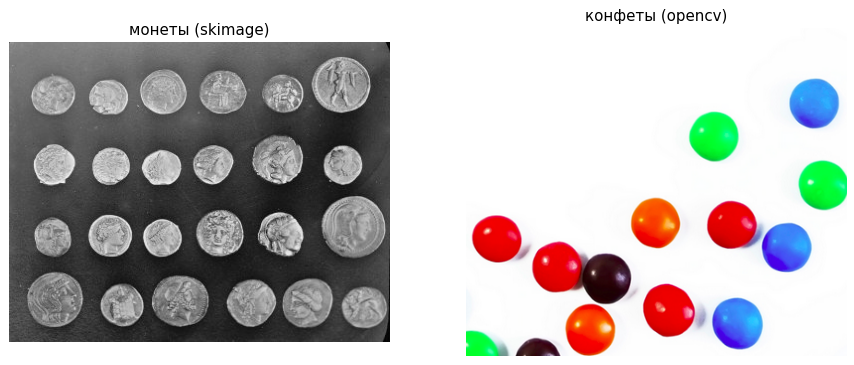

In [7]:
# --- реальные снимки ---
REAL = {}

# 1) монеты из scikit-image (серый снимок, 24 монеты разного размера, виньетирование по краям)
REAL['монеты (skimage)'] = (cv2.cvtColor(data.coins(), cv2.COLOR_GRAY2BGR), 24)

# 2) конфеты Smarties из примеров opencv (цветные, часть касается друг друга, две обрезаны краем)
url = 'https://raw.githubusercontent.com/opencv/opencv/4.x/samples/data/smarties.png'
try:
    if not os.path.exists('smarties.png'):
        urllib.request.urlretrieve(url, 'smarties.png')
    REAL['конфеты (opencv)'] = (cv2.imread('smarties.png'), 14)
except Exception as e:
    print('smarties не скачались:', e)

# число объектов во втором элементе - мой ручной подсчёт глазами
for name, (img, n_true) in REAL.items():
    print('%-20s размер %s, вручную посчитано: %d' % (name, img.shape[:2], n_true))

fig, ax = plt.subplots(1, len(REAL), figsize=(6 * len(REAL), 5))
for a, (name, (img, n_true)) in zip(np.atleast_1d(ax), REAL.items()):
    a.imshow(to_rgb(img)); a.set_title(name); a.axis('off')
plt.show()

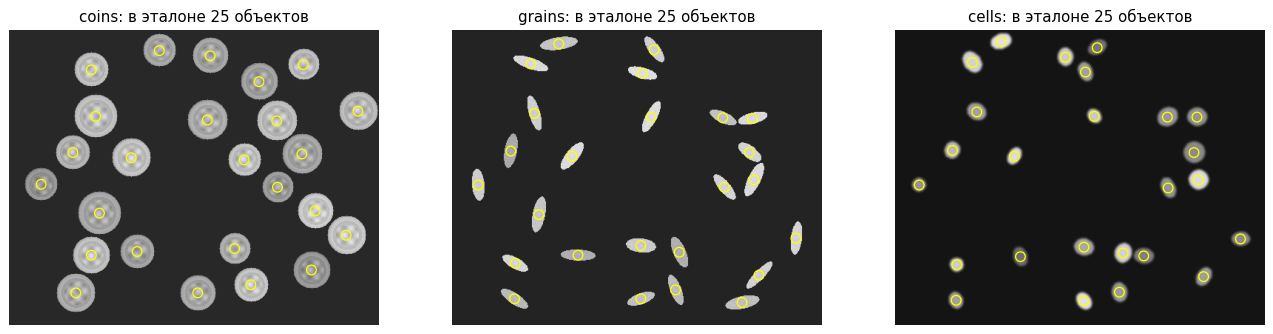

In [8]:
# примеры синтетических сцен с эталоном (жёлтые кружки - эталонные центры)
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for a, kind in zip(ax, ['coins', 'grains', 'cells']):
    img, lab, gt = make_scene(kind, seed=1, n=25)
    a.imshow(to_rgb(img)); a.scatter(gt[:, 0], gt[:, 1], s=60, facecolors='none', edgecolors='yellow')
    a.set_title('%s: в эталоне %d объектов' % (kind, len(gt))); a.axis('off')
plt.show()

Необязательный пример на настоящих ядрах клеток (флуоресцентная микроскопия, набор из `scikit-image`). Он скачивается из интернета, поэтому завёрнут в `try`: если что-то пошло не так, ноутбук просто идёт дальше.

Здесь я наступил на грабли. Сначала я просто нормировал снимок min-max, и метод нашёл только 228 ядер: на картинке видно, что большинство тусклых ядер пропущено. Ядра сильно различаются по яркости, а несколько ярких пикселей-выбросов «съедают» весь диапазон, и тусклые ядра после нормировки почти чёрные. Порог Оцу тогда видит только яркие. Поэтому перед конвейером добавил растяжку контраста (`stretch_contrast`): обрезаю выбросы по процентилям и подтягиваю тёмные тона гаммой. В ячейке считаются оба варианта, чтобы разницу было видно.

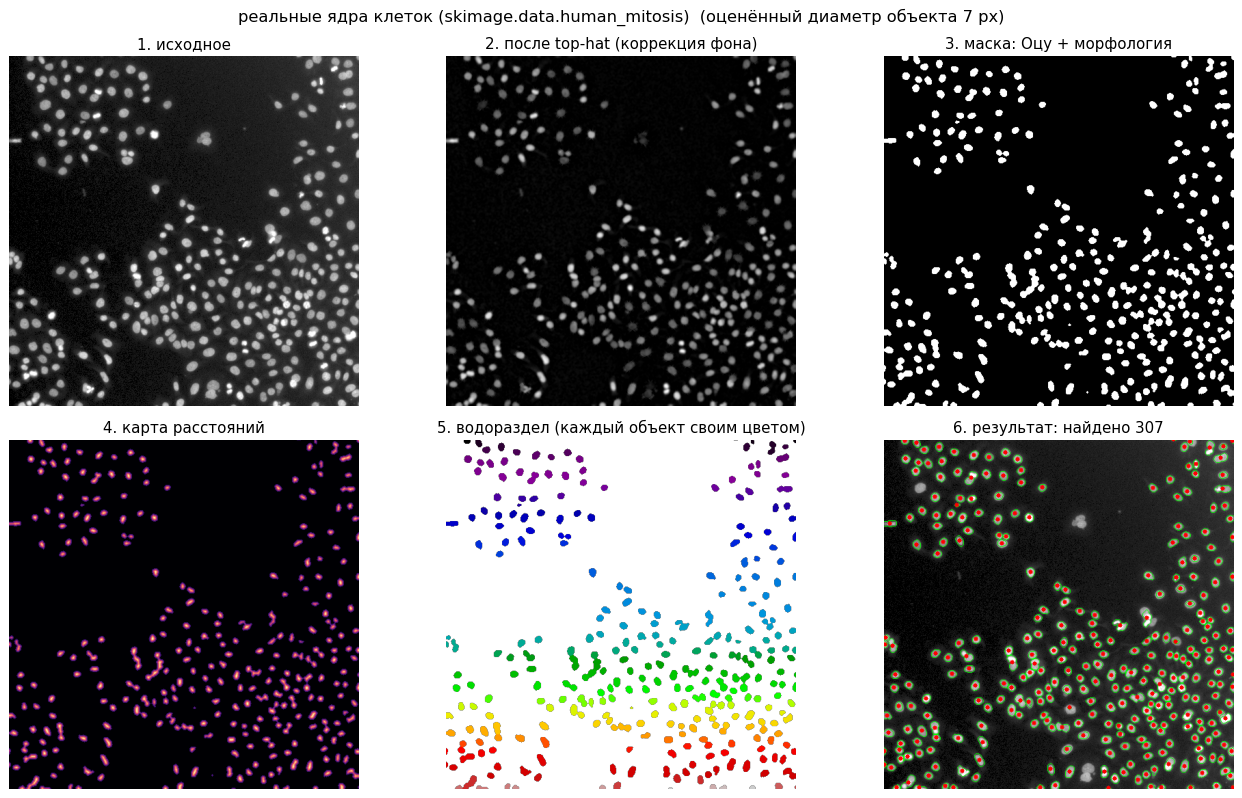

нормировка min-max:   найдено 228 (оценённый диаметр 5 px)
растяжка контраста:   найдено 307 (оценённый диаметр 7 px)


In [9]:
# Необязательный пример: реальные ядра клеток (флуоресценция) из scikit-image.
# Эталона-числа у меня для него нет, поэтому смотрим глазами на контуры.
# Ядра тут тусклые и очень разной яркости, поэтому перед конвейером делаю растяжку контраста.
try:
    mitosis = data.human_mitosis()                    # скачается при первом запуске
    # вариант 1: просто нормировка min-max (так я сначала и делал)
    raw = cv2.cvtColor(cv2.normalize(mitosis, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8), cv2.COLOR_GRAY2BGR)
    res_raw = count_objects(raw)
    # вариант 2: растяжка контраста по процентилям + гамма
    mitosis_s = stretch_contrast(mitosis)
    res_m = count_objects(mitosis_s)
    show_steps(mitosis_s, res_m, 'реальные ядра клеток (skimage.data.human_mitosis)')
    print('нормировка min-max:   найдено %d (оценённый диаметр %.0f px)' % (res_raw['n'], res_raw['diam']))
    print('растяжка контраста:   найдено %d (оценённый диаметр %.0f px)' % (res_m['n'], res_m['diam']))
except Exception as e:
    print('пример с клетками не загрузился, пропускаем:', e)

## 6. Как работает конвейер: промежуточные результаты

Для каждого снимка показаны все шаги: исходное изображение, признак после top-hat, бинарная маска, карта расстояний, результат watershed и итог с контурами (зелёные) и центрами (красные). На синтетике жёлтыми кружками отмечен эталон.

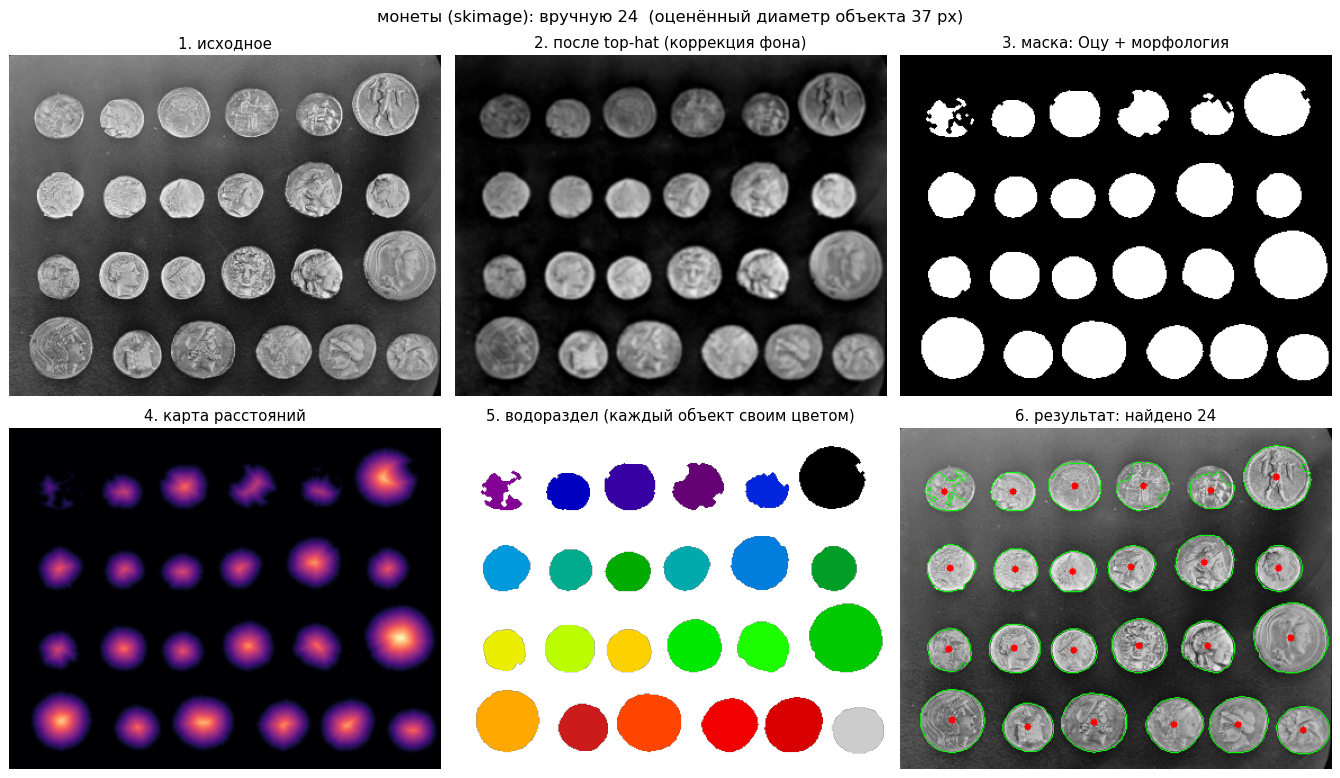

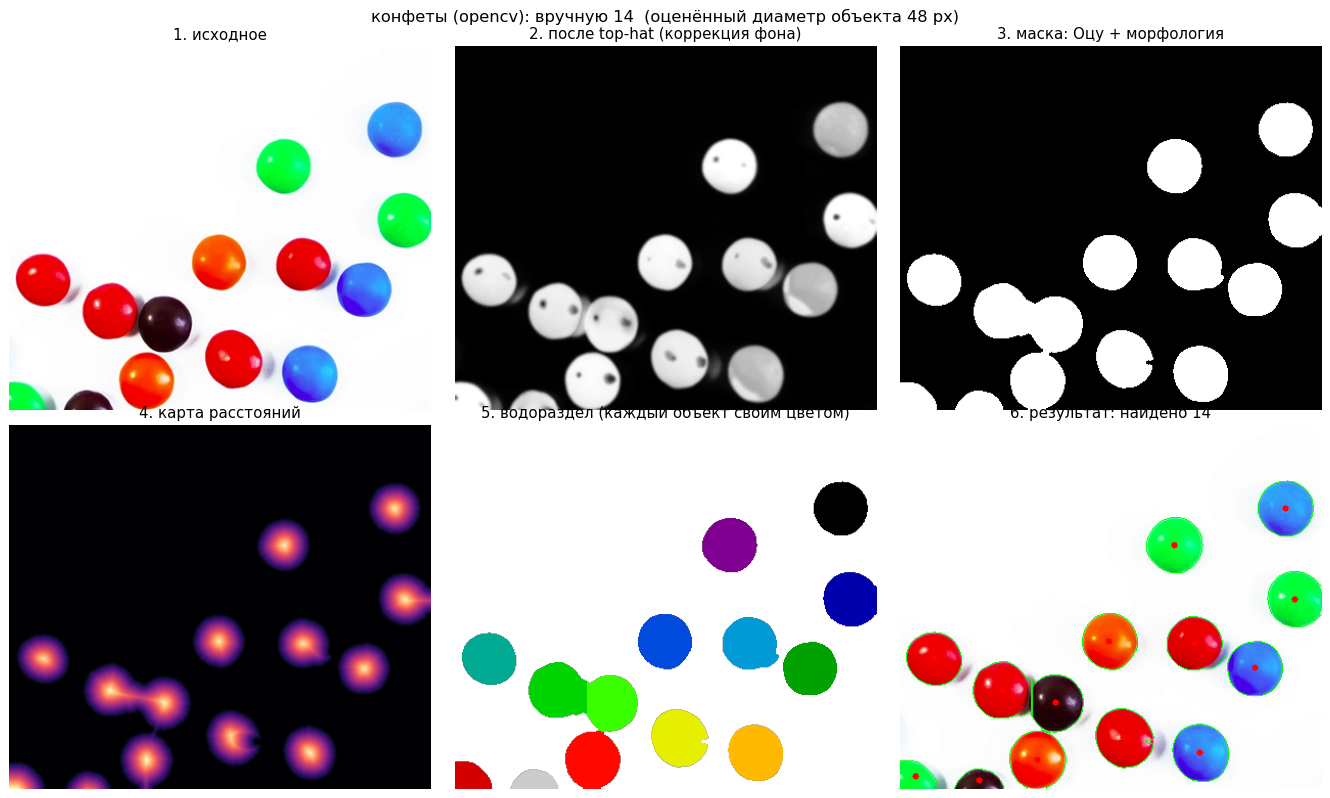

In [10]:
for name, (img, n_true) in REAL.items():
    res = count_objects(img)
    show_steps(img, res, '%s: вручную %d' % (name, n_true))

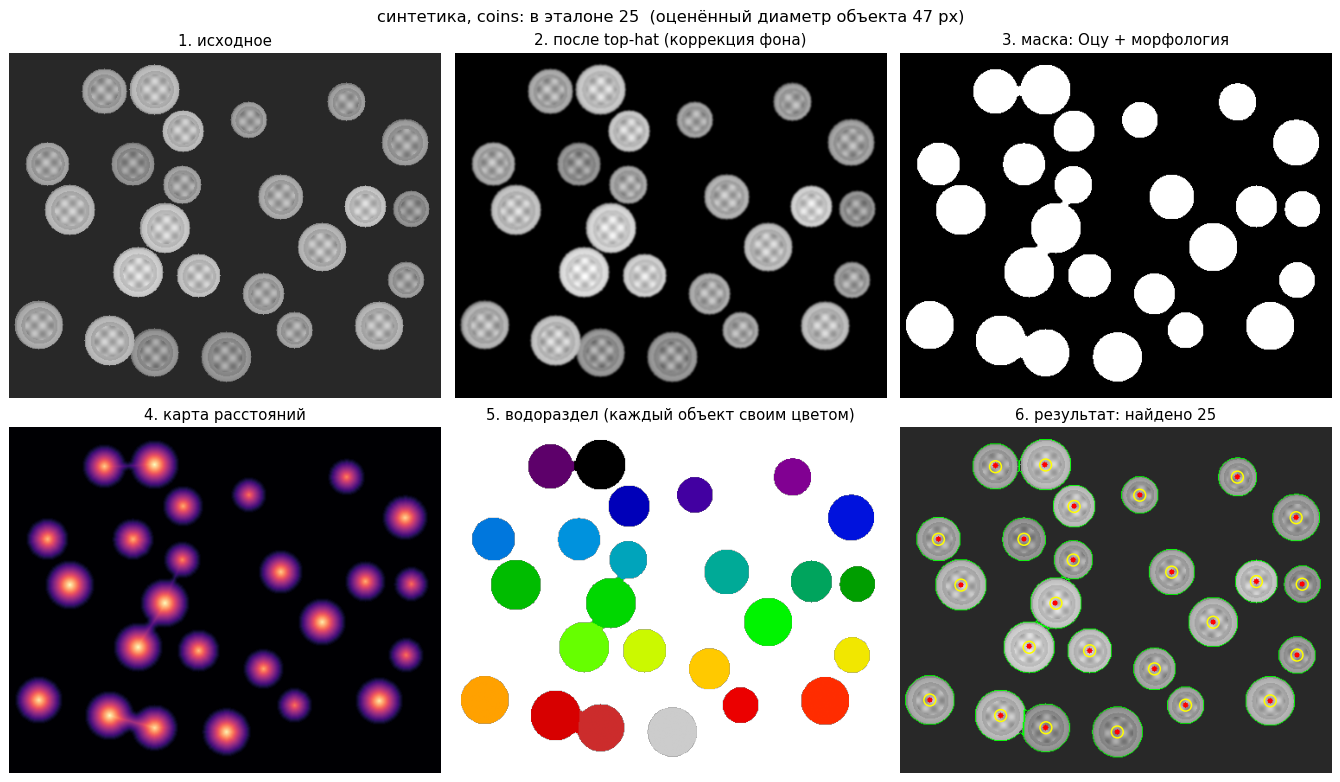

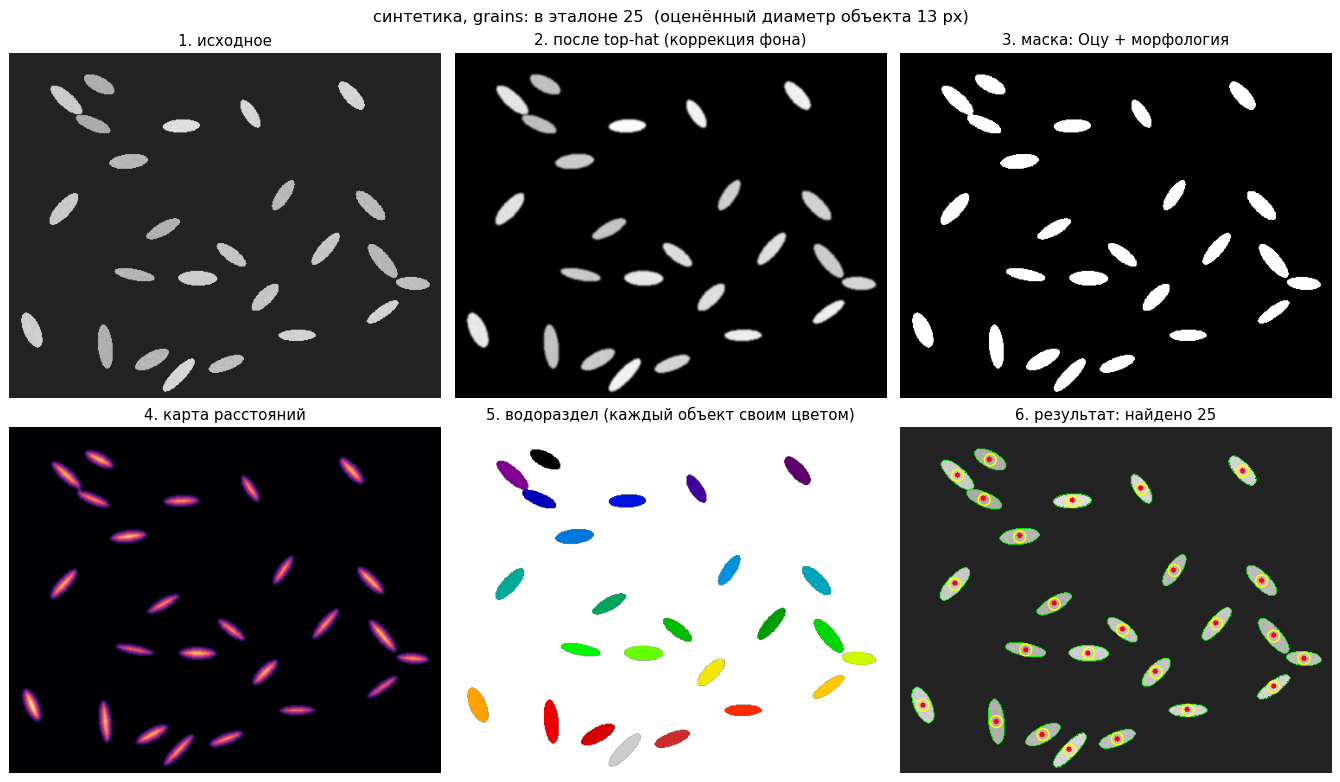

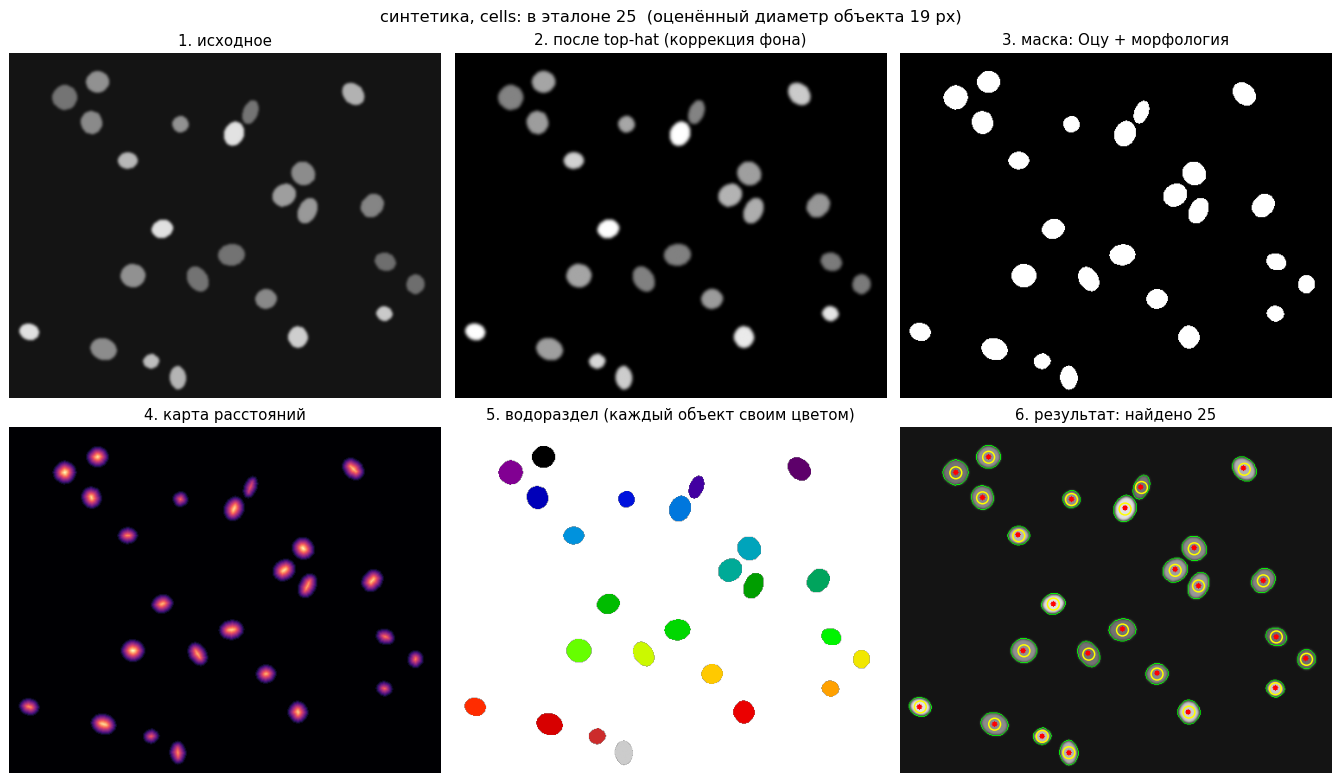

In [11]:
for kind in ['coins', 'grains', 'cells']:
    img, lab, gt = make_scene(kind, seed=2, n=25)
    res = count_objects(img)
    show_steps(img, res, 'синтетика, %s: в эталоне %d' % (kind, len(gt)), gt=gt)

## 7. Результаты

### 7.1 Реальные снимки

In [12]:
rows = []
for name, (img, n_true) in REAL.items():
    t0 = time.time()
    res = count_objects(img)
    dt = time.time() - t0
    rows.append({'снимок': name, 'вручную': n_true, 'найдено': res['n'], 'ошибка': res['n'] - n_true,
                 'диаметр, px': round(res['diam'], 1), 'время, с': round(dt, 2)})
table_real = pd.DataFrame(rows)
table_real

,снимок,вручную,найдено,ошибка,"диаметр, px","время, с"
0,монеты (skimage),24,24,0,37.4,0.35
1,конфеты (opencv),14,14,0,48.0,0.44


### 7.2 Синтетические сцены (чистые, без порчи)

По 8 случайным сценам на каждый тип, в каждой по 25 объектов. Параметры метода те же, что и на реальных снимках.

In [13]:
TOL = {'coins': 15, 'grains': 12, 'cells': 10}     # допуск совпадения центров, примерно половина размера объекта
KINDS = ['coins', 'grains', 'cells']


def run_method(img, method):
    """method: full | no_watershed | no_tophat | otsu_cc | hough"""
    if method == 'full':
        return count_objects(img)
    L, ch = get_channels(img)
    diam = auto_diam(L, ch)                  # диаметр для всех вариантов один и тот же, чтобы сравнение было честным
    if method == 'no_watershed':
        return count_objects(img, diam, use_watershed=False)
    if method == 'no_tophat':
        return count_objects(img, diam, use_tophat=False)
    if method == 'otsu_cc':
        return count_objects(img, diam, use_tophat=False, use_watershed=False)
    if method == 'hough':
        return count_hough(img, diam)
    raise ValueError(method)


def eval_synth(kind, seeds, degrade=None, method='full', h_frac=None, **scene_kw):
    """Прогоняет метод по нескольким сценам и усредняет метрики"""
    TP = FP = FN = 0
    errs, ious, times = [], [], []
    for s in seeds:
        img, lab, gt = make_scene(kind, s, **scene_kw)
        if degrade is not None:
            img = degrade(img)
        t0 = time.time()
        if h_frac is not None:
            res = count_objects(img, h_frac=h_frac)
        else:
            res = run_method(img, method)
        times.append(time.time() - t0)
        tp, fp, fn = match_centers(gt, res['centers'], TOL[kind])
        TP += tp; FP += fp; FN += fn
        errs.append(abs(res['n'] - len(gt)))
        ious.append(mean_instance_iou(lab, res['labels']))
    prec = TP / max(1, TP + FP)
    rec = TP / max(1, TP + FN)
    return dict(precision=prec, recall=rec, f1=2 * prec * rec / max(1e-9, prec + rec),
                mae=float(np.mean(errs)), iou=float(np.mean(ious)), time=float(np.mean(times)))

In [14]:
SEEDS = range(8)      # 8 разных случайных сцен на каждый тип
rows = []
for kind in KINDS:
    m = eval_synth(kind, SEEDS, n=25)
    rows.append({'тип': kind, 'precision': m['precision'], 'recall': m['recall'], 'F1': m['f1'],
                 'MAE (шт.)': m['mae'], 'IoU': m['iou'], 'время, с': m['time']})
table_synth = pd.DataFrame(rows).set_index('тип').round(3)
table_synth

,precision,recall,F1,MAE (шт.),IoU,"время, с"
тип,,,,,,
coins,1.000,1.0,1.000,0.000,0.987,0.767
grains,0.995,1.0,0.998,0.125,0.990,0.712
cells,1.000,1.0,1.000,0.000,0.931,0.668


### 7.3 Сравнение «до / после»

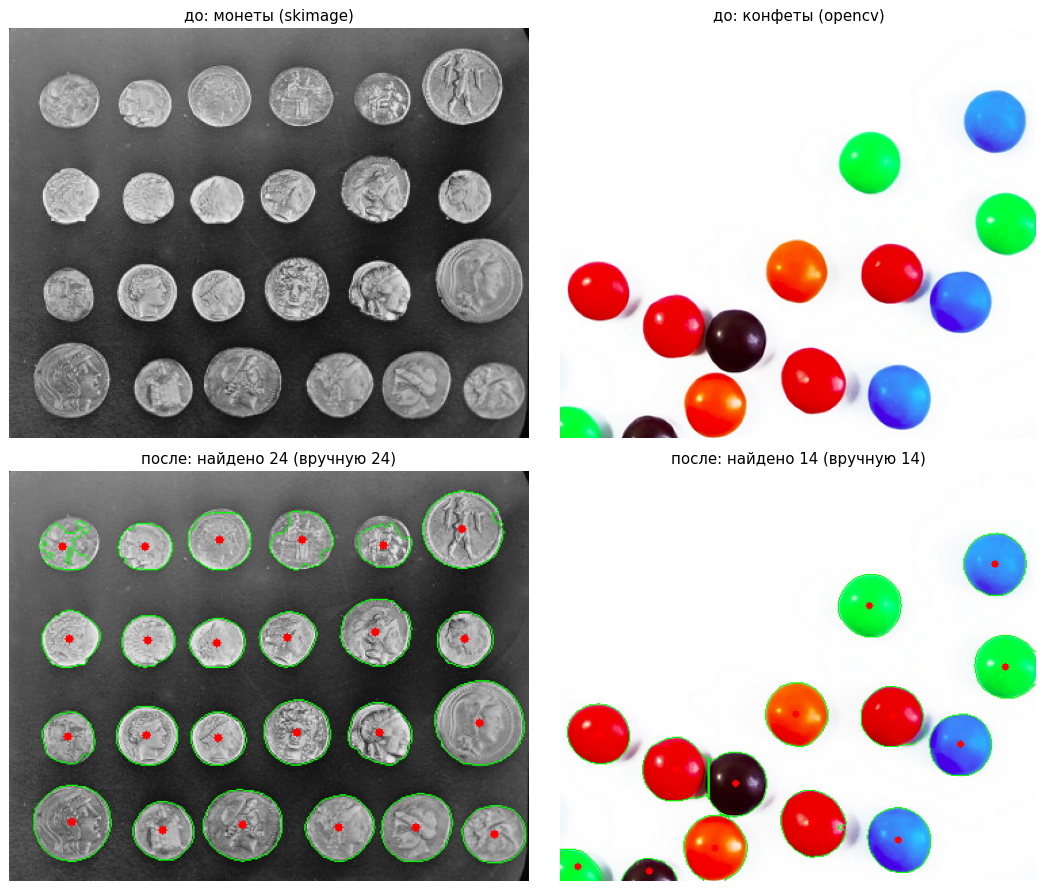

In [15]:
# сравнение "до / после" на реальных снимках
fig, ax = plt.subplots(2, len(REAL), figsize=(6 * len(REAL), 10))
for j, (name, (img, n_true)) in enumerate(REAL.items()):
    res = count_objects(img)
    ax[0, j].imshow(to_rgb(img)); ax[0, j].set_title('до: %s' % name)
    ax[1, j].imshow(to_rgb(draw_result(img, res)))
    ax[1, j].set_title('после: найдено %d (вручную %d)' % (res['n'], n_true))
    ax[0, j].axis('off'); ax[1, j].axis('off')
plt.tight_layout(); plt.show()

## 8. Сравнение вариантов метода и альтернатив

Чтобы ответить на вопрос «зачем нужен каждый шаг и почему не взять что-то проще», считаю F1 для вариантов: только Оцу и связные компоненты; плюс top-hat; плюс водораздел; полный конвейер; Хаф. Во всех вариантах диаметр объекта один и тот же (оценённый), чтобы сравнивались именно шаги, а не оценка масштаба. Три сценария: чистая сцена, сильный перепад освещения, перекрытие 30%.

In [16]:
# сравнение вариантов метода на синтетике
METHODS = [('otsu_cc', 'только Оцу + связные компоненты'),
           ('no_watershed', '+ top-hat (без водораздела)'),
           ('no_tophat', '+ водораздел (без top-hat)'),
           ('full', 'полный конвейер'),
           ('hough', 'преобразование Хафа')]
ABL_SEEDS = range(5)
scenarios = [('чистая сцена', None, {}),
             ('неравномерный свет', lambda x: add_gradient(x, 0.4, 1.5), {}),
             ('перекрытие 30%', None, {'overlap': 0.3})]

rows = []
for sc_name, deg, kw in scenarios:
    for method, mname in METHODS:
        row = {'сценарий': sc_name, 'метод': mname}
        for kind in KINDS:
            if method == 'hough' and kind == 'grains':
                row[kind] = np.nan           # окружности для вытянутых зёрен не подходят
                continue
            row[kind] = eval_synth(kind, ABL_SEEDS, degrade=deg, method=method, **kw)['f1']
        rows.append(row)
table_abl = pd.DataFrame(rows).set_index(['сценарий', 'метод']).round(2)
print('F1 для разных вариантов метода (чем ближе к 1, тем лучше)')
table_abl

F1 для разных вариантов метода (чем ближе к 1, тем лучше)


coins  grains  cells
сценарий           метод                                                
чистая сцена       только Оцу + связные компоненты   0.86    0.96   1.00
                   + top-hat (без водораздела)       0.86    0.96   1.00
                   + водораздел (без top-hat)        1.00    1.00   1.00
                   полный конвейер                   1.00    1.00   1.00
                   преобразование Хафа               1.00     NaN   0.61
неравномерный свет только Оцу + связные компоненты   0.83    0.92   0.96
                   + top-hat (без водораздела)       0.86    0.95   0.96
                   + водораздел (без top-hat)        0.93    0.95   0.97
                   полный конвейер                   0.99    0.98   0.97
                   преобразование Хафа               1.00     NaN   0.61
перекрытие 30%     только Оцу + связные компоненты   0.55    0.88   0.89
                   + top-hat (без водораздела)       0.55    0.88   0.89
                   + водораздел (без top-hat)        0.81    0.91   0.98
                   полный конвейер                   0.81    0.91   0.98
                   преобразование Хафа               1.00     NaN   0.54

## 9. Проверка на независимом размеченном датасете (BBBC038)

### 9.1 Зачем нужен чужой датасет и как я с ним работаю

В критериях к проекту прямо требуются «проверка на разных наборах изображений» и количественная оценка (точность подсчёта, IoU). До этого раздела у меня были только две реальные фотографии с ручным подсчётом и синтетика, которую я нарисовал сам. Размеченный датасет, сделанный не мной, добавляет независимую проверку. Метод остаётся классическим, задача не меняется.

Два методологических правила, которых я придерживаюсь. Первое: разметка используется только для оценки качества, на ней ничего не обучается и готовая нейросеть в решение не подставляется. Второе: параметры подбираются на одной части датасета, а итоговые цифры считаются на другой, поэтому подбор не заглядывает в тест.

Поднабор небольшой, 24 снимка из 670. Метрики: средняя абсолютная ошибка счёта, доля снимков с ошибкой не больше ±1, F1 по центрам и IoU масок. Варианты метода сравниваются те же, что в разделе 8. Диаметр и остальные параметры общие для всех снимков. Места, где метод ошибается, показаны цифрами в 9.5.

### Про датасет и как он скачивается

BBBC038 (он же Kaggle Data Science Bowl 2018; Broad Bioimage Benchmark Collection, Ljosa et al., *Nat Methods*, 2012): настоящая микроскопия ядер клеток, разные модальности (флуоресценция и гистология), разные размеры кадров. Один архив на 83 МБ, скачивается обычным `urlretrieve` за минуту-две. Разметка почти инстанционная: на каждый снимок есть папка масок, один PNG на одно ядро. Поэтому эталонное число объектов это число файлов масок, эталонные центры это центроиды масок, а IoU считается по инстанциям; дорисовывать или доопределять разметку не нужно.

Поднабор: снимки с числом ядер от 10 до 90, отсортированные по числу ядер и выбранные равномерно, чтобы попали и редкие, и плотные кадры. Каждый 4-й (6 снимков) оставлен подборочной частью для `h` и растяжки контраста, остальные 18 используются только для итоговых цифр. Снимки и маски распаковываются из архива обычным `zipfile`.


качаю архив BBBC038 (83 МБ)...
поднабор BBBC038: 24 снимка, из них 6 подборочных; ядер на снимок от 10 до 90; 4 c


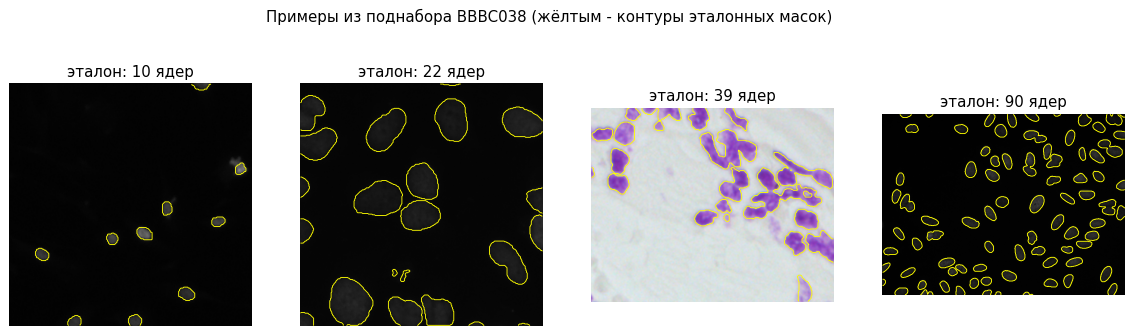

In [17]:
# --- 9.2 Поднабор датасета и его разметка ---
# BBBC038 (он же Kaggle Data Science Bowl 2018): настоящая микроскопия ядер клеток,
# один архив на 83 МБ, качается как обычно. Разметка: на каждый снимок - папка масок,
# один PNG на одно ядро. Значит эталонное число - это число файлов масок, центр ядра -
# центроид его маски, а IoU считаю по инстанциям своей же функцией из раздела 4.3.
import zipfile

BBBC038_URL = 'https://data.broadinstitute.org/bbbc/BBBC038/stage1_train.zip'
DS_DIR = 'bbbc038_subset'
DS_ZIP = os.path.join(DS_DIR, 'stage1_train.zip')
DS_N = 24                      # столько снимков беру из 670
os.makedirs(DS_DIR, exist_ok=True)


def ds_load():
    if not os.path.exists(DS_ZIP):
        print('качаю архив BBBC038 (83 МБ)...')
        urllib.request.urlretrieve(BBBC038_URL, DS_ZIP)
    z = zipfile.ZipFile(DS_ZIP)
    masks, imgs = {}, {}
    for n in z.namelist():
        if n.endswith('/'):                    # записи-каталоги в zip не нужны
            continue
        p = n.split('/')
        if len(p) == 3 and p[1] == 'masks':
            masks.setdefault(p[0], []).append(n)
        elif len(p) == 3 and p[1] == 'images':
            imgs[p[0]] = n
    cnt = {i: len(v) for i, v in masks.items() if i in imgs}
    # 24 снимка с числом ядер от 10 до 90: сортирую по числу ядер и беру равномерно,
    # чтобы в поднабор попали и редкие, и плотные кадры. Каждый 4-й - в подборочную часть.
    ids = sorted((i for i in cnt if 10 <= cnt[i] <= 90), key=lambda i: cnt[i])
    pick = [ids[int(t)] for t in np.linspace(0, len(ids) - 1, DS_N)]
    out = {}
    for k, i in enumerate(pick):
        img = cv2.imdecode(np.frombuffer(z.read(imgs[i]), np.uint8), cv2.IMREAD_UNCHANGED)
        if img.ndim == 3 and img.shape[2] == 4:                 # в архиве PNG с альфа-каналом
            img = cv2.cvtColor(img, cv2.COLOR_BGRA2BGR)
        lab = np.zeros(img.shape[:2], np.int32)                 # маски инстанций в одну карту меток
        for j, mn in enumerate(sorted(masks[i]), 1):
            m = cv2.imdecode(np.frombuffer(z.read(mn), np.uint8), cv2.IMREAD_GRAYSCALE)
            lab[m > 0] = j
        props = regionprops(lab)
        centers = np.array([(p.centroid[1], p.centroid[0]) for p in props]).reshape(-1, 2)
        diam_gt = float(np.median([2 * np.sqrt(p.area / np.pi) for p in props]))
        out[k] = dict(id=i, img=img, lab=lab, centers=centers, n_true=cnt[i],
                      tol=max(6.0, 0.5 * diam_gt),             # допуск на центр: половина ядра
                      tune=(k % 4 == 0))
    return out


try:
    t0 = time.time()
    DS = ds_load()
    print('поднабор BBBC038: %d снимка, из них %d подборочных; ядер на снимок от %d до %d; %.0f c'
          % (len(DS), sum(d['tune'] for d in DS.values()),
             min(d['n_true'] for d in DS.values()), max(d['n_true'] for d in DS.values()), time.time() - t0))
    fig, ax = plt.subplots(1, 4, figsize=(16, 4.5))
    for a, k in zip(ax, (0, 8, 16, 23)):
        d = DS[k]
        a.imshow(to_rgb(d['img']))
        a.contour(d['lab'] > 0, colors='yellow', linewidths=0.7)
        a.set_title('эталон: %d ядер' % d['n_true']); a.axis('off')
    plt.suptitle('Примеры из поднабора BBBC038 (жёлтым - контуры эталонных масок)'); plt.show()
except Exception as e:
    print('датасет не скачался, раздел 9 дальше пропускается:', e)
    DS = {}


In [18]:
# --- 9.3 Подбор двух параметров на подборочной части (6 снимков) ---
# Подбираю только то, что и так требует выбора: растяжку контраста (нужна ли она здесь,
# как в разделе 5 для микроскопии) и h водораздела (раздел 11.2). Диаметр и всё остальное -
# общие для всех снимков, как и раньше. Тестовые 18 снимков эти цифры не увидят.


def ds_image(d, prep):
    if prep == 'stretch':
        return stretch_contrast(d['img'])
    img = d['img']
    return cv2.cvtColor(img, cv2.COLOR_GRAY2BGR) if img.ndim == 2 else img


def ds_iou(res, d):
    return mean_instance_iou(d['lab'], res['labels'])          # IoU по эталонным инстанциям


if DS:
    rows = []
    for prep in ('plain', 'stretch'):
        for h in (0.05, 0.15):
            errs, ious = [], []
            for k, d in DS.items():
                if not d['tune']:
                    continue
                res = count_objects(ds_image(d, prep), h_frac=h)
                errs.append(abs(res['n'] - d['n_true']))
                ious.append(ds_iou(res, d))
            rows.append({'stretch': prep, 'h': h, 'MAE счёта': np.mean(errs), 'IoU': np.mean(ious)})
    tune_tab = pd.DataFrame(rows).round(3)
    best = tune_tab.sort_values(['MAE счёта', 'IoU'], ascending=[True, False]).iloc[0]
    DS_PREP, DS_H = best['stretch'], float(best['h'])
    print('выбрано по подборочной части: stretch=%s, h=%.2f' % (DS_PREP, DS_H))
    print(tune_tab.to_string(index=False))


выбрано по подборочной части: stretch=stretch, h=0.15
stretch    h  MAE счёта   IoU
  plain 0.05     10.000 0.408
  plain 0.15     11.500 0.397
stretch 0.05      7.667 0.549
stretch 0.15      5.667 0.538


тестовая часть BBBC038, 18 снимков:
                          метод  MAE счёта  доля |ошиб|<=1  F1 центров   IoU
только Оцу + связные компоненты     10.611           0.056       0.712 0.503
    + top-hat (без водораздела)     12.611           0.111       0.711 0.509
     + водораздел (без top-hat)      7.500           0.222       0.811 0.564
                полный конвейер     10.444           0.222       0.781 0.540
            преобразование Хафа     31.278           0.000       0.210 0.089

полный конвейер по тестовым снимкам:
  снимок  ядер  найдено  ошибка  IoU
16c3d593    11        9      -2 0.48
4193474b    12       14       2 0.14
371a6723    14       12      -2 0.60
d1dbc6ee    17        9      -8 0.35
33618678    19       18      -1 0.86
a9040135    20       77      57 0.08
43cf6b2e    23       22      -1 0.87
d8607b21    24       23      -1 0.90
1ec74a26    26       15     -11 0.25
77ceeb87    30       28      -2 0.62
f93ec5e6    32       31      -1 0.85
80632d6b    36      

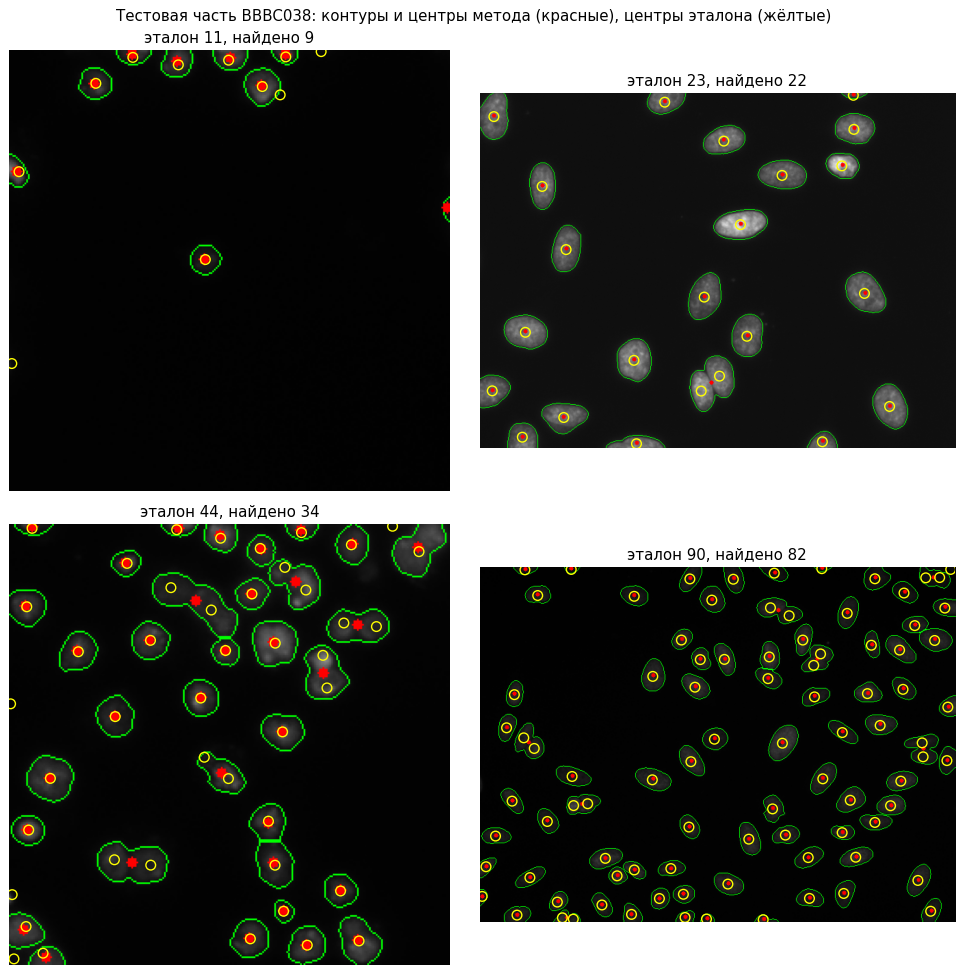

In [19]:
# --- 9.4 Итоговые цифры на тестовой части (18 снимков, параметры сюда не заходили) ---
# Те же варианты метода, что в разделе 8, но на чужих размеченных снимках.
# Метрики: MAE счёта против числа эталонных масок; доля снимков с ошибкой не больше +-1;
# F1 по центрам (допуск - половина ядра, у каждого снимка свой); IoU по эталонным инстанциям.
def ds_run(d, method):
    img = ds_image(d, DS_PREP)
    if method == 'full':
        return count_objects(img, h_frac=DS_H)
    L, ch = get_channels(img)
    diam = auto_diam(L, ch)                    # диаметр у всех вариантов один, как в разделе 8
    if method == 'no_watershed':
        return count_objects(img, diam, use_watershed=False, h_frac=DS_H)
    if method == 'no_tophat':
        return count_objects(img, diam, use_tophat=False, h_frac=DS_H)
    if method == 'otsu_cc':
        return count_objects(img, diam, use_tophat=False, use_watershed=False, h_frac=DS_H)
    if method == 'hough':
        return count_hough(img, diam)
    raise ValueError(method)


if DS:
    TEST = [(k, d) for k, d in DS.items() if not d['tune']]
    rows = []
    for method, mname in METHODS:
        mae, ok1, ious, tp = [], [], [], [0, 0, 0]
        for k, d in TEST:
            res = ds_run(d, method)
            mae.append(abs(res['n'] - d['n_true']))
            ok1.append(abs(res['n'] - d['n_true']) <= 1)
            t = match_centers(d['centers'], res['centers'], d['tol'])
            tp = [a + b for a, b in zip(tp, t)]
            ious.append(ds_iou(res, d))
        prec = tp[0] / max(1, tp[0] + tp[1]); rec = tp[0] / max(1, tp[0] + tp[2])
        rows.append({'метод': mname, 'MAE счёта': np.mean(mae), 'доля |ошиб|<=1': np.mean(ok1),
                     'F1 центров': 2 * prec * rec / max(1e-9, prec + rec), 'IoU': np.mean(ious)})
    table_ds = pd.DataFrame(rows).round(3)
    print('тестовая часть BBBC038, 18 снимков:')
    print(table_ds.to_string(index=False))

    # полный конвейер по каждому тестовому снимку: где именно провалы
    rows = []
    for k, d in TEST:
        res = ds_run(d, 'full')
        rows.append({'снимок': d['id'][:8], 'ядер': d['n_true'], 'найдено': res['n'],
                     'ошибка': res['n'] - d['n_true'], 'IoU': round(ds_iou(res, d), 2)})
    table_ds_id = pd.DataFrame(rows)
    print('\nполный конвейер по тестовым снимкам:')
    print(table_ds_id.to_string(index=False))

    # помог ли подбор на датасете: исходные параметры метода против подобранных на поднаборе
    def cfg_eval(prep, h):
        mae, ok1, ious, tp = [], [], [], [0, 0, 0]
        for k, d in TEST:
            res = count_objects(ds_image(d, prep), h_frac=h)
            mae.append(abs(res['n'] - d['n_true']))
            ok1.append(abs(res['n'] - d['n_true']) <= 1)
            t = match_centers(d['centers'], res['centers'], d['tol'])
            tp = [a + b for a, b in zip(tp, t)]
            ious.append(ds_iou(res, d))
        prec = tp[0] / max(1, tp[0] + tp[1]); rec = tp[0] / max(1, tp[0] + tp[2])
        return {'MAE счёта': np.mean(mae), 'доля |ошиб|<=1': np.mean(ok1),
                'F1 центров': 2 * prec * rec / max(1e-9, prec + rec), 'IoU': np.mean(ious)}

    table_cfg = pd.DataFrame([
        dict(config='исходные параметры метода (до датасета): plain, h=0.15', **cfg_eval('plain', 0.15)),
        dict(config='подобрано на поднаборе датасета: %s, h=%.2f' % (DS_PREP, DS_H), **cfg_eval(DS_PREP, DS_H)),
    ]).round(3)
    print('\nметод без датасета и с подбором на датасете (тестовые 18 снимков):')
    print(table_cfg.to_string(index=False))

    fig, ax = plt.subplots(2, 2, figsize=(11, 11))
    for a, (k, d) in zip(ax.ravel(), [TEST[0], TEST[len(TEST) // 3], TEST[2 * len(TEST) // 3], TEST[-1]]):
        res = ds_run(d, 'full')
        a.imshow(to_rgb(draw_result(ds_image(d, 'plain'), res)))
        a.scatter(d['centers'][:, 0], d['centers'][:, 1], s=60, facecolors='none', edgecolors='yellow', lw=1.1)
        a.set_title('эталон %d, найдено %d' % (d['n_true'], res['n'])); a.axis('off')
    plt.suptitle('Тестовая часть BBBC038: контуры и центры метода (красные), центры эталона (жёлтые)')
    plt.tight_layout(); plt.show()


### 9.5 Что видно на этом датасете

* Цифры скромнее, чем на моей синтетике: синтетика «гладкая», а здесь настоящая микроскопия с шумом, текстурой и разной модальностью. Полный конвейер: MAE счёта 10.4, IoU по инстанциям 0.54; ошибка не больше 1 ядра на 4 снимках из 18, не больше 2 на 8 из 18.
* Водораздел оправдан и на чужих данных: без него (Оцу + связные компоненты) MAE 10.6 и F1 центров 0.71, с водоразделом 7.5-10.4 и F1 0.78-0.81: связные компоненты склеивают касающиеся ядра, водораздел их разделяет.
* Top-hat на этих данных вредит: 10.4 с ним против 7.5 без него. По-видимому, на кадрах с крупными тёмными структурами фона (гистология) оценка фона ядром в два диаметра «съедает» часть самих ядер. В разделе 8 top-hat выигрывал на неравномерном свете синтетики; на чужих реальных данных его польза не универсальна. Без сравнения на стороннем датасете этот эффект был бы не виден.
* Хаф к ядрам неприменим (MAE 31.3, IoU 0.09): ядра не круги с чётким контуром.
* Провалы видны по отдельным снимкам. a9040135: при 20 ядрах найдено 77, это гистологический кадр с текстурным фоном, маска получается из кусков фона и дробится на лишние «объекты». cbff6036: найдено 36 из 76, и 5ef4442e: найдено 30 из 54, там очень плотные ядра слипаются в кластеры, на карте расстояний нет «седловины», водоразделу нечем резать; это то же ограничение, что в разделе 11.1, но подтверждённое на чужой разметке. На спокойной флуоресценции в то же время ошибка 1-2 ядра при IoU 0.85-0.90 (снимки 33618678, 43cf6b2e, d8607b21, f93ec5e6, b76ff33a).
* На подборочной части растяжка контраста выиграла у простой нормировки (MAE 5.7 против 10.0): на настоящей тусклой микроскопии она нужна, как и в разделе 5. Значения stretch и h подобраны на 6 снимках, тестовые 18 для подбора не использовались.

На независимой инстанционной разметке классический конвейер считает ядра с ошибкой в пару штук на спокойных кадрах и ошибается на плотных кластерах и текстурной гистологии. Это границы применимости метода, подтверждённые экспериментом на чужих данных.


In [20]:
# --- 9.6 Выгрузка всех метрик в zip: csv + txt + png ---
# Сохраняю все таблицы метрик в трёх форматах (csv, txt, png-график), плюс README и
# оверлей тестовых снимков, и пакую в архив project_metrics.zip. В колабе архив
# скачивается на компьютер, вне колаба остаётся лежать рядом с ноутбуком.
EXPORT_DIR = 'metrics_export'
ZIP_NAME = 'project_metrics.zip'
TABLES = [('table_real', '7.1 реальные снимки: ручной подсчёт против метода'),
          ('table_synth', '7.2 синтетические сцены без порчи'),
          ('table_abl', '8 F1 вариантов метода на трёх сценариях'),
          ('tune_tab', '9.3 подбор stretch и h на подборочной части'),
          ('table_ds', '9.4 варианты метода на тесте BBBC038 (18 снимков)'),
          ('table_ds_id', '9.4 полный конвейер по каждому тестовому снимку'),
          ('table_cfg', '9.4 исходные параметры против подбора на датасете')]
if DS:
    os.makedirs(EXPORT_DIR, exist_ok=True)
    saved, missing = [], []
    for name, title in TABLES:
        tab = globals().get(name)
        if not isinstance(tab, pd.DataFrame):
            missing.append(name)                      # ячейка с этой таблицей не запускалась
            continue
        tab.to_csv(os.path.join(EXPORT_DIR, name + '.csv'))
        with open(os.path.join(EXPORT_DIR, name + '.txt'), 'w') as f:
            f.write(title + '\n' + tab.to_string() + '\n')
        num = tab.reset_index(drop=True).select_dtypes('number')
        fig, ax = plt.subplots(figsize=(max(6.0, 0.5 * len(num) + 3), 4))
        num.plot.bar(ax=ax, width=0.8)
        ax.set_title(title, fontsize=9)
        ax.set_xticklabels([str(i) for i in tab.index], rotation=45, ha='right', fontsize=7)
        ax.tick_params(axis='y', labelsize=7)
        fig.tight_layout()
        fig.savefig(os.path.join(EXPORT_DIR, name + '.png'), dpi=110)
        plt.close(fig)
        saved.append(name)

    # png: полный конвейер на четырёх тестовых снимках поверх исходных кадров
    fig, ax = plt.subplots(2, 2, figsize=(11, 11))
    for a, (k, d) in zip(ax.ravel(), [(k, d) for k, d in DS.items() if not d['tune']][::5]):
        res = ds_run(d, 'full')
        a.imshow(to_rgb(draw_result(ds_image(d, 'plain'), res)))
        a.scatter(d['centers'][:, 0], d['centers'][:, 1], s=60, facecolors='none', edgecolors='yellow', lw=1.1)
        a.set_title('эталон %d, найдено %d' % (d['n_true'], res['n'])); a.axis('off')
    fig.tight_layout()
    fig.savefig(os.path.join(EXPORT_DIR, 'bbbc038_overlay.png'), dpi=110)
    plt.close(fig)
    saved.append('bbbc038_overlay')

    with open(os.path.join(EXPORT_DIR, 'README.txt'), 'w') as f:
        f.write('Метрики проекта «Подсчёт объектов», выгрузка из раздела 9.6.\n')
        f.write('Каждая таблица лежит в трёх файлах: .csv (данные), .txt (как напечатано в ноутбуке), .png (график).\n')
        f.write('Состав:\n')
        for name, title in TABLES:
            if name in saved:
                f.write('  %s - %s\n' % (name, title))
        f.write('  bbbc038_overlay.png - результат полного конвейера на 4 тестовых снимках BBBC038\n')
        f.write('Таблицы, которых нет в этом запуске (их ячейки не выполнялись): %s\n'
                % (', '.join(missing) if missing else 'нет'))

    with zipfile.ZipFile(ZIP_NAME, 'w', zipfile.ZIP_DEFLATED) as z:
        for fn in sorted(os.listdir(EXPORT_DIR)):
            z.write(os.path.join(EXPORT_DIR, fn), fn)
    print('в %s: таблиц %d x 3 формата + оверлей + README%s' % (
        ZIP_NAME, len(saved) - 1,
        ('; не попали: %s - их ячейки не запускались в этом прогоне' % ', '.join(missing)) if missing else ''))
    print('размер архива %.0f КБ' % (os.path.getsize(ZIP_NAME) / 1024))
    try:
        from google.colab import files
        files.download(ZIP_NAME)
    except ImportError:
        print('это не колаб: архив лежит рядом с ноутбуком')


в project_metrics.zip: таблиц 7 x 3 формата + оверлей + README
размер архива 867 КБ


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 10. Тестирование и устойчивость

### 10.1 Влияние условий съёмки (синтетика)

Каждое условие меняется по одному параметру при остальных чистых. По 5 сцен на точку, 25 объектов в сцене.

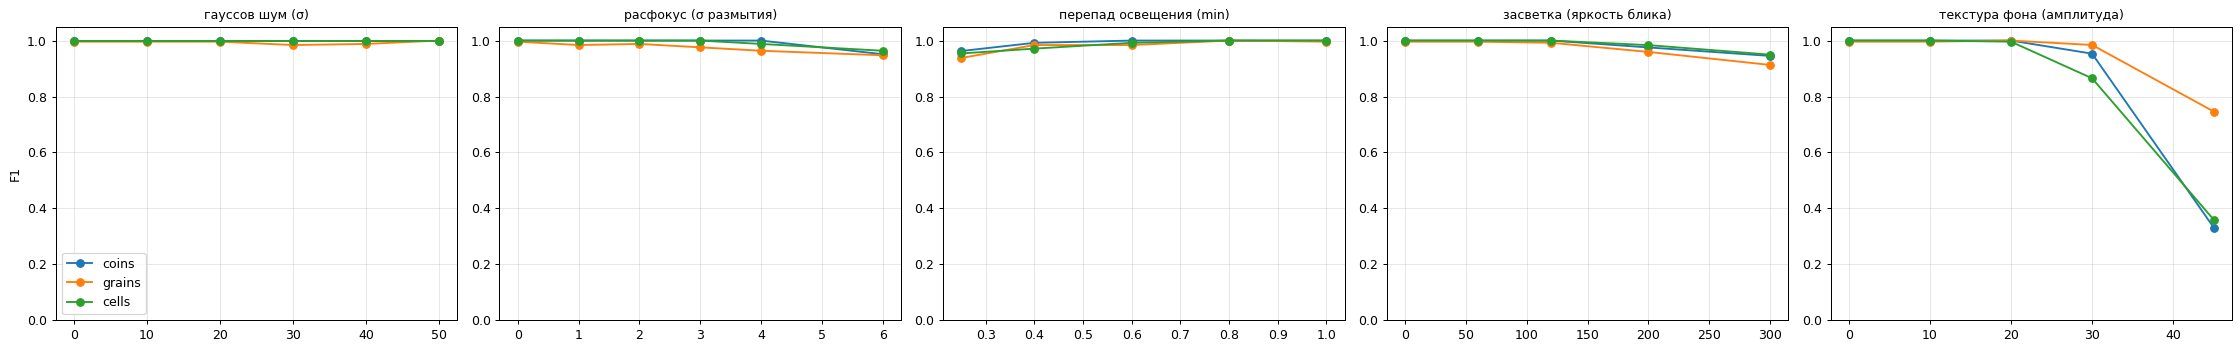

In [21]:
# устойчивость: как падает качество при ухудшении условий
ROB_SEEDS = range(5)
families = {
    'гауссов шум (σ)':        [(s, (lambda x, s=s: add_noise(x, s))) for s in [0, 10, 20, 30, 40, 50]],
    'расфокус (σ размытия)':  [(s, (lambda x, s=s: add_blur(x, s) if s else x)) for s in [0, 1, 2, 3, 4, 6]],
    'перепад освещения (min)': [(lo, (lambda x, lo=lo: add_gradient(x, lo, 1.5))) for lo in [1.0, 0.8, 0.6, 0.4, 0.25]],
    'засветка (яркость блика)': [(s, (lambda x, s=s: add_glare(x, s))) for s in [0, 60, 120, 200, 300]],
    'текстура фона (амплитуда)': [(a, (lambda x, a=a: add_texture(x, a) if a else x)) for a in [0, 10, 20, 30, 45]],
}
rob = {}
fig, axes = plt.subplots(1, len(families), figsize=(5 * len(families), 4))
for ax_i, (fam, levels) in zip(axes, families.items()):
    for kind in KINDS:
        f1s = [eval_synth(kind, ROB_SEEDS, degrade=fn, n=25)['f1'] for _, fn in levels]
        rob[(fam, kind)] = f1s
        ax_i.plot([l for l, _ in levels], f1s, marker='o', label=kind)
    ax_i.set_title(fam, fontsize=10); ax_i.set_ylim(0, 1.05); ax_i.grid(alpha=0.3)
axes[0].set_ylabel('F1'); axes[0].legend()
plt.tight_layout(); plt.show()

Самые тяжёлые уровни порчи и результат на них (пример на зёрнах):

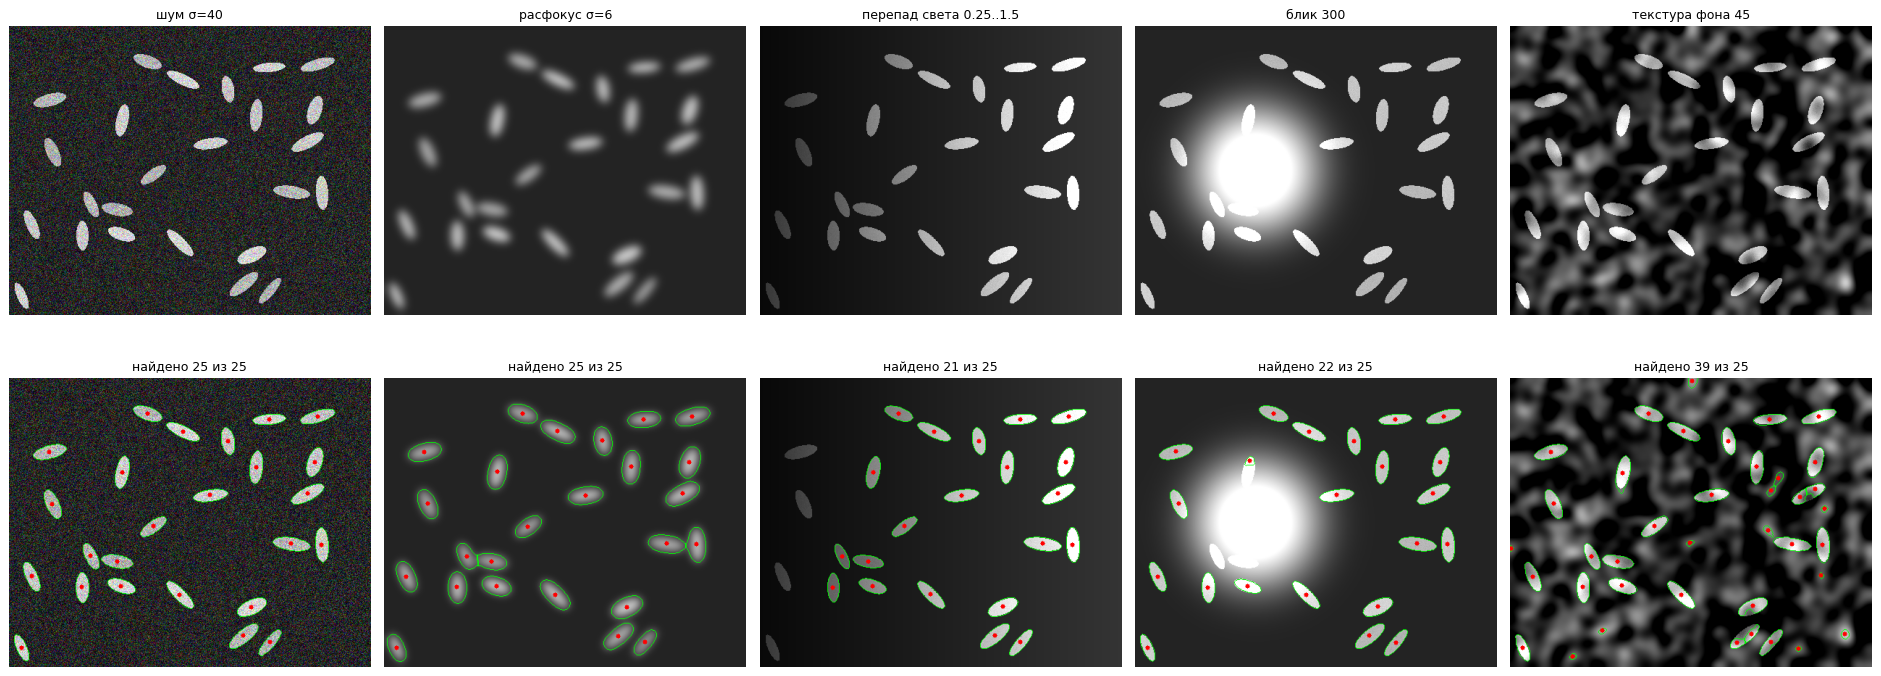

In [22]:
# как выглядят самые тяжёлые варианты и что находит метод
bad = [('шум σ=40', lambda x: add_noise(x, 40)),
       ('расфокус σ=6', lambda x: add_blur(x, 6)),
       ('перепад света 0.25..1.5', lambda x: add_gradient(x, 0.25, 1.5)),
       ('блик 300', lambda x: add_glare(x, 300)),
       ('текстура фона 45', lambda x: add_texture(x, 45))]
fig, ax = plt.subplots(2, len(bad), figsize=(4.2 * len(bad), 8.5))
for j, (nm, fn) in enumerate(bad):
    img, lab, gt = make_scene('grains', 3, n=25)
    img2 = fn(img)
    res = count_objects(img2)
    ax[0, j].imshow(to_rgb(img2)); ax[0, j].set_title(nm, fontsize=10)
    ax[1, j].imshow(to_rgb(draw_result(img2, res))); ax[1, j].set_title('найдено %d из %d' % (res['n'], len(gt)), fontsize=10)
    ax[0, j].axis('off'); ax[1, j].axis('off')
plt.tight_layout(); plt.show()

### 10.2 Те же испытания на реальных снимках

Реальные снимки портятся теми же функциями. В скобках указано число объектов, посчитанное вручную.

In [23]:
# то же самое на реальных снимках: портим их и смотрим, сколько находится
conds = [('исходный', lambda x: x),
         ('шум σ=25', lambda x: add_noise(x, 25)),
         ('расфокус σ=3', lambda x: add_blur(x, 3)),
         ('перепад света', lambda x: add_gradient(x, 0.4, 1.5)),
         ('блик', lambda x: add_glare(x, 150)),
         ('текстура фона', lambda x: add_texture(x, 20))]
rows = []
for cname, fn in conds:
    row = {'условие': cname}
    for name, (img, n_true) in REAL.items():
        row[name + ' (вручную %d)' % n_true] = count_objects(fn(img))['n']
    rows.append(row)
pd.DataFrame(rows).set_index('условие')

,монеты (skimage) (вручную 24),конфеты (opencv) (вручную 14)
условие,,
исходный,24,14
шум σ=25,23,14
расфокус σ=3,24,14
перепад света,18,14
блик,2,14
текстура фона,23,14


Сильный блик на реальных монетах даёт всего 2 из 24. Ниже разбираю, что там происходит.

In [24]:
# почему сильный блик ломает реальные монеты? Смотрю, что именно оценил метод
coins_img = REAL['монеты (skimage)'][0]
for nm, strength in [('без блика', 0), ('слабый блик (60)', 60), ('сильный блик (150)', 150)]:
    im = add_glare(coins_img, strength) if strength else coins_img
    L, ch = get_channels(im)
    t, _ = otsu(L)
    res = count_objects(im)
    print('%-20s светлых пикселей %.0f%%, "объекты светлее фона": %-5s, диаметр %.0f px, найдено %d из 24'
          % (nm, 100 * (L > t).mean(), res['bright'], res['diam'], res['n']))

без блика            светлых пикселей 43%, "объекты светлее фона": True , диаметр 37 px, найдено 24 из 24
слабый блик (60)     светлых пикселей 44%, "объекты светлее фона": True , диаметр 37 px, найдено 24 из 24
сильный блик (150)   светлых пикселей 50%, "объекты светлее фона": False, диаметр 214 px, найдено 2 из 24


### 10.3 Нестандартные случаи

Пустой кадр с шумом (должно быть 0), один объект, очень плотная сцена и очень мелкие объекты.

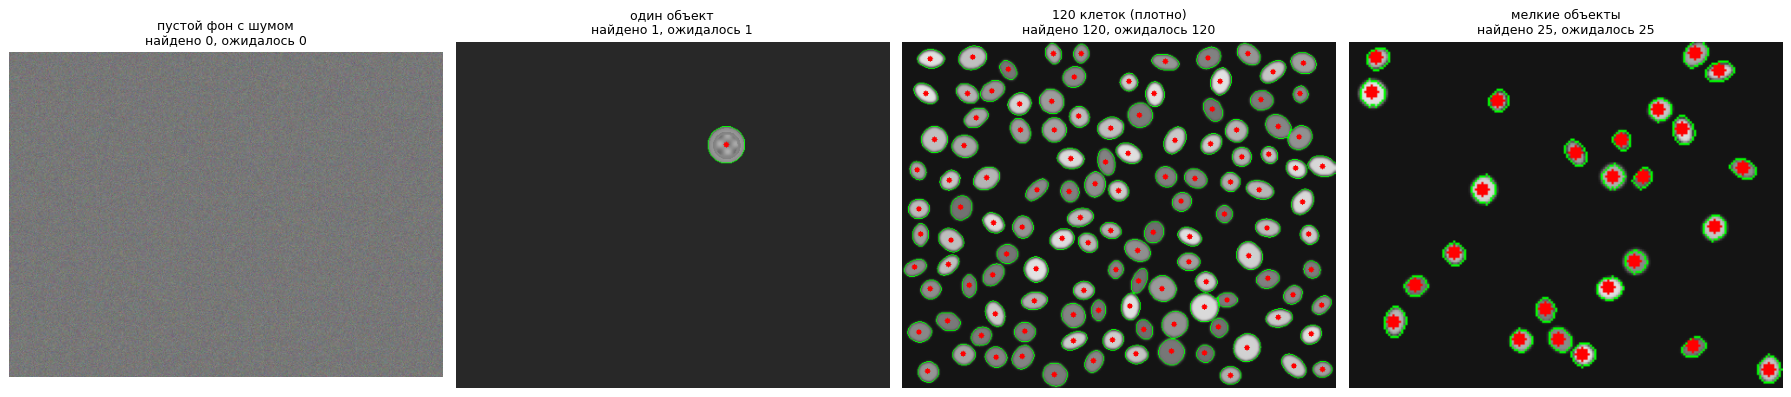

In [25]:
# нестандартные случаи: пустой кадр, один объект, объекты на краю, очень мелкие объекты
img_empty = add_noise(np.full((300, 400, 3), 120, np.uint8), 8)
img_one, _, _ = make_scene('coins', 0, n=1)
img_dense, lab_d, gt_d = make_scene('cells', 0, n=120)             # очень много объектов
img_small, _, gt_small = make_scene('cells', 0, n=25, size=(400, 500))
img_small = cv2.resize(img_small, None, fx=0.4, fy=0.4, interpolation=cv2.INTER_AREA)   # мелкие объекты (диаметр ~ 11 px)

cases = [('пустой фон с шумом', img_empty, 0), ('один объект', img_one, 1),
         ('120 клеток (плотно)', img_dense, len(gt_d)), ('мелкие объекты', img_small, len(gt_small))]
fig, ax = plt.subplots(1, len(cases), figsize=(5 * len(cases), 4.5))
for a, (nm, im, n_true) in zip(ax, cases):
    res = count_objects(im)
    a.imshow(to_rgb(draw_result(im, res))); a.axis('off')
    a.set_title('%s\nнайдено %d, ожидалось %d' % (nm, res['n'], n_true), fontsize=10)
plt.tight_layout(); plt.show()

## 11. Ограничения метода (проверка экспериментом)

### 11.1 Перекрытие объектов

Сравниваем полный метод и вариант без водораздела при растущем перекрытии (0.3 значит, что центры двух объектов ближе друг к другу на 30% диаметра, то есть они сильно налезают).

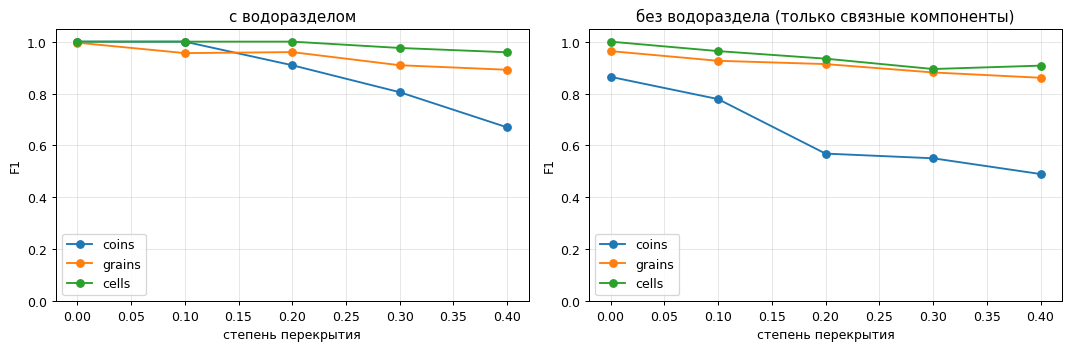

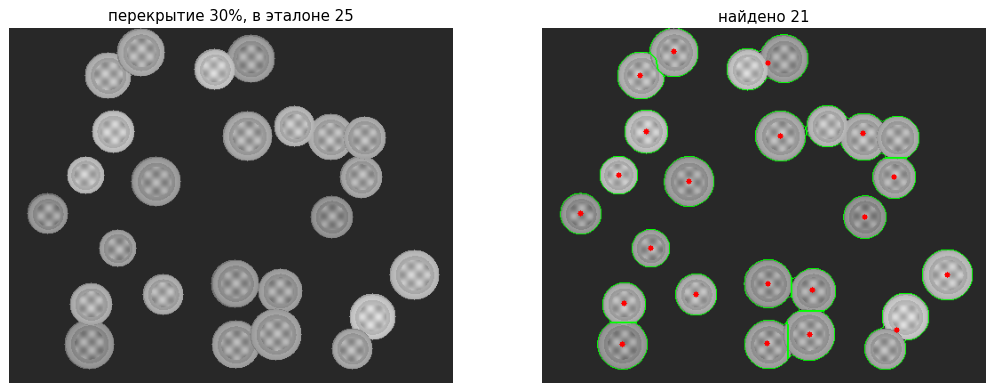

In [26]:
# ограничение 1: перекрытие объектов. Смотрим, как водораздел справляется с налезающими объектами
ovs = [0.0, 0.1, 0.2, 0.3, 0.4]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for kind in KINDS:
    f_ws = [eval_synth(kind, range(5), overlap=o, method='full')['f1'] for o in ovs]
    f_cc = [eval_synth(kind, range(5), overlap=o, method='no_watershed')['f1'] for o in ovs]
    axes[0].plot(ovs, f_ws, marker='o', label=kind)
    axes[1].plot(ovs, f_cc, marker='o', label=kind)
axes[0].set_title('с водоразделом'); axes[1].set_title('без водораздела (только связные компоненты)')
for a in axes:
    a.set_xlabel('степень перекрытия'); a.set_ylabel('F1'); a.set_ylim(0, 1.05); a.grid(alpha=0.3); a.legend()
plt.tight_layout(); plt.show()

# пример: монеты с перекрытием 30%
img, lab, gt = make_scene('coins', 1, n=25, overlap=0.3)
res = count_objects(img)
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
ax[0].imshow(to_rgb(img)); ax[0].set_title('перекрытие 30%%, в эталоне %d' % len(gt))
ax[1].imshow(to_rgb(draw_result(img, res))); ax[1].set_title('найдено %d' % res['n'])
for a in ax: a.axis('off')
plt.show()

### 11.2 Параметр h в водоразделе

`h` (доля диаметра) задаёт, насколько глубокой должна быть «впадина» между двумя вершинами карты расстояний, чтобы считать их разными объектами. Меньшее `h` разрезает сильнее перекрытые объекты, большее начинает склеивать соседей. Смотрю, как F1 зависит от `h` на обычных сценах и при перекрытии 30%.

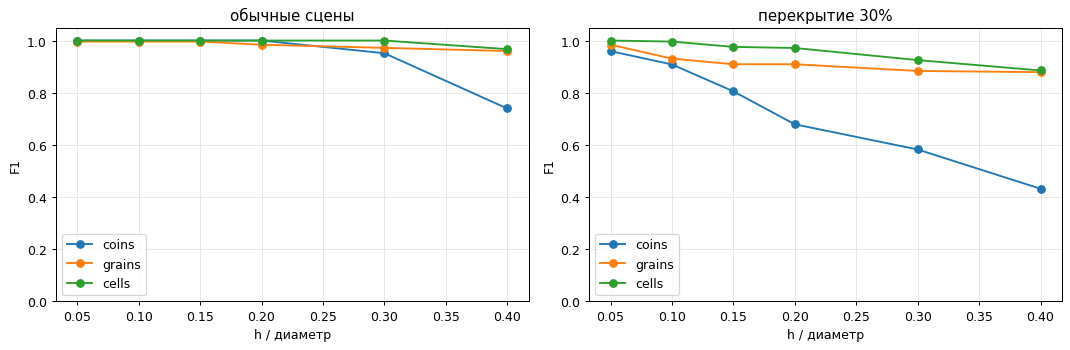

In [27]:
# ограничение 2: параметр h (глубина "впадины" между объектами, при которой их считаем разными)
hs = [0.05, 0.1, 0.15, 0.2, 0.3, 0.4]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for kind in KINDS:
    clean = [eval_synth(kind, range(5), h_frac=h)['f1'] for h in hs]
    over = [eval_synth(kind, range(5), h_frac=h, overlap=0.3)['f1'] for h in hs]
    axes[0].plot(hs, clean, marker='o', label=kind)
    axes[1].plot(hs, over, marker='o', label=kind)
axes[0].set_title('обычные сцены'); axes[1].set_title('перекрытие 30%')
for a in axes:
    a.set_xlabel('h / диаметр'); a.set_ylabel('F1'); a.set_ylim(0, 1.05); a.grid(alpha=0.3); a.legend()
plt.tight_layout(); plt.show()

### 11.3 Чувствительность к масштабу

Автоматическая оценка диаметра сравнивается с истинным размером, а потом проверяется, что будет, если подать в метод диаметр, неверный в разы.

автоматическая оценка диаметра (среднее по 5 сценам) vs истинный размер:
  coins   оценка 44.9 px, истинный размер ~ 48 px
  grains  оценка 13.4 px, истинный размер ~ 16 px
  cells   оценка 18.1 px, истинный размер ~ 18 px


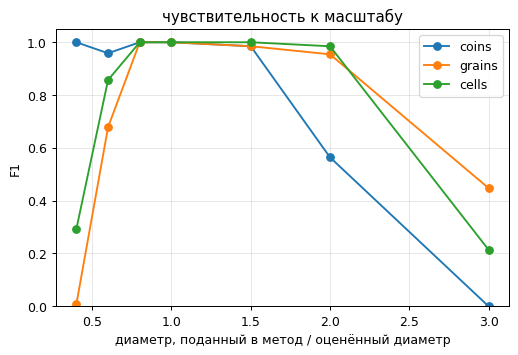

In [28]:
# ограничение 3: масштаб объекта (диаметр). Метод сам его оценивает, но что будет, если он ошибётся?
true_diam = {'coins': 48, 'grains': 16, 'cells': 18}      # примерные истинные размеры в синтетике (для grains - ширина)
est = {}
for kind in KINDS:
    est[kind] = np.mean([count_objects(make_scene(kind, s)[0])['diam'] for s in range(5)])
print('автоматическая оценка диаметра (среднее по 5 сценам) vs истинный размер:')
for kind in KINDS:
    print('  %-7s оценка %.1f px, истинный размер ~ %d px' % (kind, est[kind], true_diam[kind]))

factors = [0.4, 0.6, 0.8, 1.0, 1.5, 2.0, 3.0]
plt.figure(figsize=(6.5, 4))
for kind in KINDS:
    f1s = []
    for f in factors:
        TP = FP = FN = 0
        for s in range(4):
            img, lab, gt = make_scene(kind, s)
            res = count_objects(img, diam=est[kind] * f)
            tp, fp, fn = match_centers(gt, res['centers'], TOL[kind])
            TP += tp; FP += fp; FN += fn
        f1s.append(2 * TP / max(1, 2 * TP + FP + FN))
    plt.plot(factors, f1s, marker='o', label=kind)
plt.xlabel('диаметр, поданный в метод / оценённый диаметр')
plt.ylabel('F1'); plt.ylim(0, 1.05); plt.grid(alpha=0.3); plt.legend()
plt.title('чувствительность к масштабу'); plt.show()

## 12. Свои фотографии

Здесь можно загрузить любое фото (монеты на столе, горсть риса, снимок клеток) и посмотреть работу программы. Фото уменьшается до 900 px по большей стороне. Если знаете настоящее число объектов, впишите его в `true_counts`.

Два параметра, которые стоит знать:

* `DIAM`: если метод неверно оценил размер объекта (в заголовке рисунка написан «оценённый диаметр»), впишите примерный диаметр объекта в пикселях. Из раздела 11.3 видно, что ошибка масштаба до полутора раз терпима, а больше уже нет.
* `STRETCH = True` для тусклых снимков с микроскопа (см. раздел 5).
* Каждое фото прогоняется сразу в нескольких конфигурациях и сводится в одну таблицу: «до датасета» (параметры до раздела 9: plain, h=0.15), «после датасета» (stretch и h, подобранные на поднаборе BBBC038) и режим Хафа для круглых объектов. Подробные рисунки шагов - по `MODE_DRAW` (по умолчанию 'both').
* Если метод сильно ошибся в размере (в заголовке рисунка написан «оценённый диаметр»), впишите `DIAM`: на фото со слипшимися монетами автодиаметр считается по слипшемуся пятну и завышен, а Хаф с ручным диаметром находит большую часть монет (раздел 13, пункт 8).

Советы для хорошего результата: свет без сильных бликов, фон однотонный, камера сверху. Плотные кучи объектов разного цвета на текстурном фоне метод считать не умеет (см. раздел 13).

Saving U4zKzCdW2iA.jpg to U4zKzCdW2iA.jpg


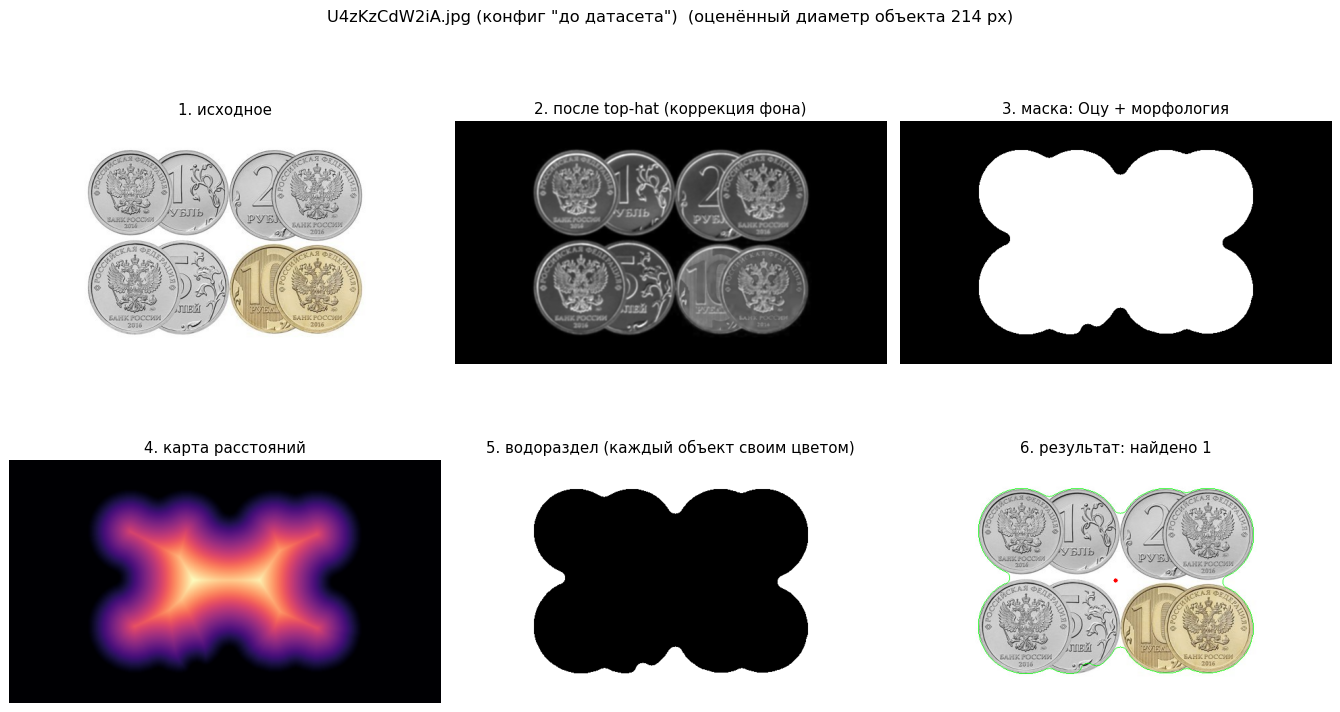

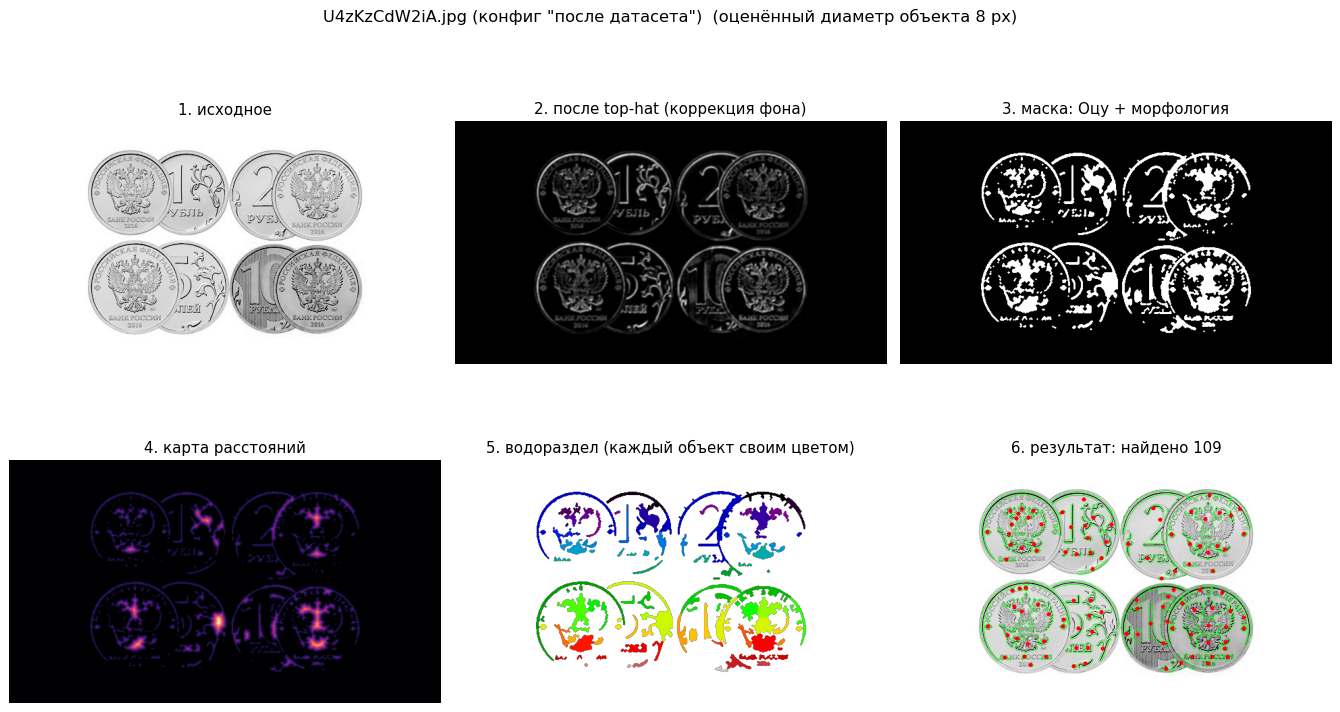

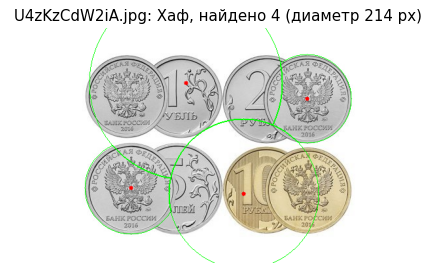

U4zKzCdW2iA.jpg
сводка по своим фото (эталон - ваш ручной подсчёт, если он вписан в true_counts):
           фото         конфиг      метод  найдено  диаметр, px  время, с
U4zKzCdW2iA.jpg    до датасета водораздел        1          214      0.91
U4zKzCdW2iA.jpg после датасета водораздел      109            8      1.37
U4zKzCdW2iA.jpg  Хаф по кругам        хаф        4          214      3.38


In [29]:
# Свои фотографии. Запустить ячейку, выбрать файлы (jpg/png) - каждое фото проходит через
# конвейер сразу в нескольких конфигурациях, и результаты сводятся в одну таблицу:
#   "до датасета"  - параметры, которые метод имел до раздела 9 (plain, h=0.15);
#   "после датасета" - stretch и h, подобранные на поднаборе BBBC038 в разделе 9.3
#                    (если раздел 9 не запускался - совпадает с "до датасета");
#   "хаф"         - режим Хафа для круглых объектов (монеты); если автодиаметр уехал
#                   (на слипшихся монетах он считается по слипшемуся пятну), впишите DIAM.
# Подробные рисунки шагов - для конфигураций, указанных в MODE_DRAW.
true_counts = {}          # например {'rice.jpg': 87}
DIAM = None               # если метод ошибся с размером объекта: диаметр в пикселях (например 40)
STRETCH = False           # принудительная растяжка контраста для всех конфигураций (тусклая микроскопия)
MODE_DRAW = 'both'        # 'both' / 'before' / 'after' / 'none': каким конфигурациям рисовать шаги

try:
    from google.colab import files
    uploaded = files.upload()
    own_files = list(uploaded.keys())
except ImportError:
    own_files = []        # не колаб - кладём фото рядом с ноутбуком и перечисляем имена вручную
    print('это не колаб: укажите имена файлов в own_files')

def load_image(path, max_side=900):
    """читает фото и уменьшает до max_side по большей стороне (быстрее и стабильнее параметры)"""
    img = cv2.imdecode(np.fromfile(path, dtype=np.uint8), cv2.IMREAD_COLOR)
    h, w = img.shape[:2]
    if max(h, w) > max_side:
        k = max_side / max(h, w)
        img = cv2.resize(img, None, fx=k, fy=k, interpolation=cv2.INTER_AREA)
    return img

def prepare(img, prep):
    return stretch_contrast(img) if (STRETCH or prep == 'stretch') else img

CFG = [('до датасета', 'plain', 0.15)]
if 'DS_PREP' in globals():
    CFG.append(('после датасета', DS_PREP, DS_H))
else:
    print('раздел 9 не запускался: конфигурация "после датасета" совпадает с "до датасета"')
    CFG.append(('после датасета', 'plain', 0.15))

rows = []
for fname in own_files:
    img0 = load_image(fname)
    manual = (', вручную %d' % true_counts[fname]) if fname in true_counts else ''
    for tag, prep, h in CFG:
        img = prepare(img0, prep)
        t0 = time.time()
        res = count_objects(img, diam=DIAM, h_frac=h)
        rows.append({'фото': fname, 'конфиг': tag, 'метод': 'водораздел', 'найдено': res['n'],
                     'диаметр, px': int(round(res['diam'])), 'время, с': round(time.time() - t0, 2)})
        if MODE_DRAW == 'both' or (MODE_DRAW == 'before' and tag == 'до датасета') \
           or (MODE_DRAW == 'after' and tag == 'после датасета'):
            show_steps(img, res, '%s (конфиг "%s")' % (fname, tag))
    # Хаф: от stretch и h не зависит, важен только диаметр
    L, ch = get_channels(img0)
    dh = DIAM if DIAM else auto_diam(L, ch)
    res_h = count_hough(img0, dh)
    rows.append({'фото': fname, 'конфиг': 'Хаф по кругам', 'метод': 'хаф', 'найдено': res_h['n'],
                 'диаметр, px': int(round(dh)), 'время, с': round(time.time() - t0, 2)})
    if MODE_DRAW != 'none':
        plt.figure(figsize=(6, 5))
        plt.imshow(to_rgb(draw_result(img0, res_h)))
        plt.title('%s: Хаф, найдено %d (диаметр %d px)' % (fname, res_h['n'], dh))
        plt.axis('off'); plt.show()
    print('%s%s' % (fname, manual))
table_own = pd.DataFrame(rows)
print('сводка по своим фото (эталон - ваш ручной подсчёт, если он вписан в true_counts):')
print(table_own.to_string(index=False))


## 13. Выводы

**Что получилось.** Сделал программу подсчёта объектов на классических методах: цветовые каналы, top-hat, порог Оцу с морфологией, distance transform и watershed по h-максимумам. Размер объекта оценивается автоматически, параметры одинаковые для монет, зёрен и клеток. Одна картинка обрабатывается примерно за 0.2-0.5 секунды на CPU (в колабе время может отличаться).

**Результаты (цифры из запуска выше):**

* Реальные снимки: монеты 24 из 24, конфеты Smarties 14 из 14 (эталон: мой ручной подсчёт).
* Синтетика без порчи: F1 = 1.00 (монеты), 0.998 (зёрна), 1.00 (клетки); средняя ошибка счёта не больше 0.125 объекта на сцену. IoU масок 0.99 / 0.99 / 0.93. У клеток IoU ниже, потому что у них размытая граница и разная яркость, и порог Оцу режет их по среднему уровню.
* Шум до σ=50 и расфокус до σ=6 на синтетике почти не снижают F1 (около 0.95 и выше). Перепад освещения и блик до 300 по яркости тоже терпимы, но слабее: самое низкое значение F1 около 0.91 (зёрна при блике 300). В примере с зёрнами при перепаде света находится 21 из 25, при блике 22 из 25.
* Нестандартные случаи: пустой кадр с шумом даёт 0, один объект даёт 1, 120 плотно лежащих клеток найдены все 120, мелкие объекты (около 11 px) найдены все 25.
* **Реальные ядра клеток** (`human_mitosis`, ячейка в разделе 5): с обычной min-max нормировкой метод нашёл 228 ядер и пропустил много тусклых, с растяжкой контраста по процентилям - 307. Это число подтверждено прогоном в колабе на настоящем файле: контуры стоят почти на всех ядрах, включая тусклые, оценённый диаметр около 7 px выглядит разумно. Точного эталона у этого снимка нет, поэтому 307 остаётся моей визуальной оценкой, но уже посчитанной на оригинале, а не на скриншоте.

**Зачем каждый шаг (раздел 8).** Просто Оцу и связные компоненты дают F1 = 0.86 на монетах даже на чистой сцене, а при перекрытии 30% падают до 0.55. Водораздел поднимает монеты до 1.00 на чистой сцене и до 0.81 при перекрытии. Top-hat даёт меньший выигрыш: при сильном перепаде света монеты 0.93 → 0.99 и зёрна 0.95 → 0.98. Хаф для окружностей на монетах отработал лучше всех (F1 = 1.00 даже при перекрытии 30%), но для зёрен он вообще не подходит, а на клетках F1 только 0.54-0.61. Поэтому для задачи с тремя типами объектов я выбрал водораздел: он единственный не привязан к форме круга. Если бы нужны были только монеты, Хаф был бы разумной альтернативой.

**Ограничения, которые я нашёл экспериментом:**

1. **Перекрытие.** Для монет F1 держится на 1.0 до перекрытия 0.1, потом падает: 0.91 (0.2), 0.81 (0.3), 0.67 (0.4). Когда объекты налезают сильно, на карте расстояний нет «седловины», и watershed нечего резать.
2. **Блик на реальных монетах.** Сильный блик (150) даёт 2 из 24. Причина разобрана в разделе 10.2: светлых пикселей становится ровно половина, эвристика «объекты - меньшая часть изображения» переворачивается, и диаметр оценивается в 214 px вместо 37. Слабый блик (60) проблем не создаёт. Это слабое место: полярность определяется по доле пикселей.
3. **Перепад света на реальных монетах:** 18 из 24, часть монет теряется. Скорее всего (я это отдельно не проверял) у самых тёмных монет слишком маленький контраст относительно фона после top-hat, и они не проходят порог Оцу.
4. **Сильная текстура фона.** При амплитуде 45 F1 падает до 0.33 для монет и клеток и 0.75 для зёрен. Фон начинает выглядеть как объекты.
5. **Масштаб.** Автооценка диаметра немного занижает размер (монеты 44.9 vs около 48, зёрна 13.4 vs ширина 16, клетки 18.1 vs 18). Метод терпит ошибку масштаба примерно в диапазоне от 0.8 до 1.5 раза, дальше качество быстро падает. Один и тот же масштаб на весь кадр, поэтому смесь очень разных по размеру объектов он не поддержит. На реальных мелких ядрах оценка тоже получилась маленькой (5-7 px), поэтому для микроскопии стоит смотреть на «оценённый диаметр» в заголовке рисунка и при необходимости задавать `DIAM` вручную.
6. **Сложная фотография: кучка конфет-шоколадок на тёмном текстурном фоне.** Я загрузил такое фото в раздел 12, и метод нашёл 67 объектов, хотя по моей прикидке по скриншоту их примерно 25-30. Диаметр он оценил в 13 px вместо примерно 50. Здесь нарушены сразу все допущения из раздела 1: объекты и светлее, и темнее фона (белый и тёмный шоколад), они лежат плотной кучей, фон шероховатый, формы разные (круги, ромбы, треугольники). В результате маска получается кусками фона, и водораздел её дробит. Это не баг, а границы применимости классического подхода; такие сцены нужно решать нейросетью.
7. **Налёгшие круглые монеты: реальное фото монет на деревянном столе.** Загрузил в раздел 12: водораздел нашёл 5 монет при моём ручном подсчёте 16 (8 золотистых и 8 серебристых). Монеты лежат внахлёст, маска слипается в одно пятно без «перешейков», водоразделу резать нечего, а автооценка диаметра (79 px) посчиталась по этому слипшемуся пятну. Хаф на этом фото работает намного лучше: на уменьшенной вырезке он нашёл 14 из 16 почти одинаково при подставном диаметре 50-60 px, тогда как водораздел с ручным диаметром 50-55 дал 6-7 (лучший результат 11 при `h = 0.05`). Числа 6-7, 11 и 14 получены на уменьшенной вырезке, на оригинале они будут другими - теперь это можно перепроверить одним прогоном: в таблице раздела 12 есть строка Хафа, а диаметр можно задать вручную через `DIAM`. Случай согласуется с разделом 8: на круглых перекрывающихся объектах Хаф лучше водораздела, но на зёрнах и клетках Хаф не работает, поэтому основной режим оставлен водораздельный.
8. **Фото 8 монет, касающихся парами, на светлом фоне.** В разделе 12 водораздел нашёл 1 объект при ручном подсчёте 8: маска - одно связное пятно, на карте расстояний между монетами нет «седловин», а один широкий гребень, поэтому не помогает даже h=0.05 (проверено на прокси-сцене, повторяющей раскладку фото: все конфигурации водораздела дают 1 из 8). Оценённый диаметр 214 px на этом фото примерно равен диаметру монеты, то есть проблема не в масштабе, а в разделении; на прокси-сцене автодиаметр завышен ещё сильнее (351 при истинном 200). На таких фото лучше работает строка Хафа в таблице раздела 12 с ручным DIAM: с истинным диаметром Хаф на прокси находит 6 из 8, с автодиаметром - 2 из 8. Глубокое перекрытие круглых объектов - граница применимости водораздела: там нужен Хаф с заданным размером или нейросеть.

**Что я не проверил:**

* На BBBC038 (раздел 9), настоящей микроскопии с разметкой по инстанциям, полный конвейер даёт MAE счёта 10.4 при IoU 0.54, вариант без top-hat - 7.5: на спокойных кадрах ошибка 1-2 ядра (IoU 0.85-0.90), провалы на плотных кластерах и текстурной гистологии (раздел 11.1). Без водораздела MAE 10.6 и F1 центров 0.71, Хаф - MAE 31.3. Top-hat на этих данных скорее вредит, чем помогает.
* Все таблицы метрик выгружаются ячейкой раздела 9.6 в архив project_metrics.zip (csv, txt, png-графики и README): цифры можно приложить к защите, не открывая ноутбук.
* Реальных снимков с проверенным числом объектов у меня только два (серый и цветной). Для настоящих зёрен проверки нет вообще. Для клеток это частично закрыто разделом 9: там число и маски пришли из разметки датасета, а не из моих глаз. Раздел 12 нужно использовать для проверки на своих фото.
* Про параметр `h`: на синтетике значения 0.05-0.15 работают одинаково хорошо на обычных сценах, а меньшее `h` даже лучше разделяет перекрытые объекты. Я оставил 0.15 как более осторожное значение, но на реальных снимках с рельефом (где вершины на карте расстояний «шумят») меньшее `h` может начать дробить объекты. Это я не проверял.

**Что можно улучшить дальше:** определять полярность не по доле светлых пикселей (например, по краям кадра с запасом на объекты на краях); подстраивать порог локально (по окнам), чтобы вытянуть тёмные монеты при перепаде света; оценивать диаметр по нескольким масштабам, чтобы не зависеть от слипшихся пятен (пункт 8) и работать со смесью размеров; разделять глубоко перекрывающиеся объекты не только по «седловинам» карты расстояний (например, маркерами по кривизне контура пятна). Растяжка контраста теперь включается сама в конфигурации «после датасета» (раздел 12), Хаф как отдельный режим и сравнение конфигураций «до/после датасета» уже встроены в таблицу раздела 12.

## 14. Источники и материалы

1. Gonzalez R., Woods R. *Digital Image Processing* (глава про морфологию и сегментацию): top-hat, пороговая обработка Оцу, водораздел.
2. Otsu N. A threshold selection method from gray-level histograms, 1979.
3. Beucher S., Meyer F. The morphological approach to segmentation: the watershed transformation, 1993.
4. Документация OpenCV (`morphologyEx`, `HoughCircles`, `threshold`), scikit-image (`watershed`, `h_maxima`, `regionprops`).
5. Данные: `skimage.data.coins`, `skimage.data.human_mitosis` (scikit-image), `smarties.png` из примеров OpenCV (github.com/opencv/opencv, samples/data).
6. Датасет BBBC038 (Kaggle Data Science Bowl 2018): Ljosa V. et al. The Broad Bioimage Benchmark Collection, *Nature Methods*, 2012. Файлы: data.broadinstitute.org/bbbc/BBBC038 (архив 83 МБ, скачивается обычным способом).